<!-- d2l:prose id=retrieval-md-1 fw=all -->

# Sparse, Dense and Approximate Retrieval

At the end of that section we had an embedder that puts
a passage answering almost any question about this book among the ten
nearest. We found those passages in the simplest way there is, by comparing
the question's vector with every passage's vector: for one book, a single
matrix product. Two doubts remain. Would the same product serve a library,
where every question reads every stored vector? And what about a question
that names a function, such as `load_array`? A vector records what a
passage is about, and it may prefer one that merely discusses the subject.

Search engines met both problems long before neural networks. For exact
words they built the word index, which lists for every word the passages
that contain it, and ranked those passages by BM25, a rule from the
mid-1990s that is still the default of the Lucene search library. For size
they gave up exactness: an *approximate nearest-neighbor* index looks at a
small fraction of the vectors and accepts that it sometimes misses the
nearest one. We have met BM25 already, as the floor of
that section that found 96% of the questions; this
section opens it up.

Both old answers still hold. A word index and a vector index fail on
different questions, so a good retriever keeps both, merges their rankings
and lets a slower model reorder the top few. For a large collection, an
approximate index gives up a little recall for a great deal of speed and
memory. We build each piece and end with the retriever that the rest of
this part calls.

Four setup cells come first, and a first reading can skip them. They pin
the chapter's embedder, Qwen3-Embedding-0.6B, and Qwen3-Reranker-0.6B,
which reads a question and a passage together. Results that take minutes to
compute are stored with their settings; setting `D2L_RERUN` regenerates
them.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import bm25s
import collections
import faiss
import hashlib
import json
import os
import pandas as pd
import platform
import pytrec_eval
import re
import time
import transformers
import warnings

In [3]:
EMB, RERANKER = d2l.DEFAULT_EMBEDDER, 'Qwen/Qwen3-Reranker-0.6B'
GPU = torch.cuda.is_available()
SMALL = not GPU  # the CPU path: fewer questions embedded and reranked live
DTYPE, DEVICE = (torch.bfloat16, 'cuda') if GPU else (torch.float32, 'cpu')
ARTIFACTS = {  # name: (stored key, the file a regeneration writes)
    'ret-stress-emb': ('lm-enc-r3-stress-emb-v1', 'lm-enc-r3-stress-emb.npz'),
    'ret-rerank': ('lm-enc-ret-rerank-v2', 'lm-enc-ret-rerank.json'),
    'ret-ann': ('lm-enc-ann-v1', 'lm-enc-ann.json')}
RERUN = d2l.lm_rerun(ARTIFACTS)
assert GPU or not RERUN & {'ret-stress-emb', 'ret-rerank'}, \
    'encoding and reranking for a regeneration need a GPU'
K_RRF, DEPTH = 60, 100  # fusion constant; candidates kept per retriever
RR_DEPTHS, RR_MAX_LEN, RR_BATCH = (20, 100), 1024, 32  # reranked prefixes
RR_LIVE = None if GPU else 8  # dev questions reranked live (None: all)
N_TUNE_DENSE = None if GPU else 1_000  # train questions embedded for fusion
BM25_GRID = dict(k1=(0.9, 1.2, 1.5, 2.0), b=(0.4, 0.75, 0.9),
                 split_identifiers=(True, False))
LAMBDAS = (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)  # dense weight
STRESS_N = None  # all; 20_000 is the reduced path for small machines
N_NQ_QUERIES, N_WARM, BUILD_THREADS = 1_000, 100, 8
NLIST = 1024 if STRESS_N is None else 128  # IVF cells: about sqrt(16 N)
NPROBES = (1, 2, 4, 8, 16, 32, 64)
PQ_MS, PQ_SEEDS = (64, 32), (0, 1, 2)  # sub-vectors; k-means seeds
HNSW_M, EF_CONSTRUCTION, EF_SEARCHES = 32, 200, (16, 32, 64, 128, 256)
QUERY = d2l._EMBEDDERS[EMB]  # pooling, padding side, query format
NQ_TASK = ('Given a web search query, retrieve relevant passages that '
           'answer the query')  # the model card's task for web questions
REV = {m: d2l.HF_ENCODER_REVISIONS[m] for m in (EMB, RERANKER)}
faiss.omp_set_num_threads(BUILD_THREADS)  # builds; timed searches use one
CONFIG = {  # what each result is made with; reading it checks this
    'ret-stress-emb': dict(model=EMB, revision=REV[EMB],
                           corpus=d2l.R3_VERSION, nq_skip=20_000,
                           n_queries=N_NQ_QUERIES, task=NQ_TASK, max_len=512),
    'ret-rerank': dict(model=RERANKER, revision=REV[RERANKER], embedder=EMB,
                       embedder_revision=REV[EMB], corpus=d2l.R3_VERSION,
                       bm25=d2l.BookRetriever.BM25_PARAMS, k_rrf=K_RRF,
                       depths=RR_DEPTHS, max_len=RR_MAX_LEN, batch=RR_BATCH,
                       instruction=d2l.BOOK_TASK, view='dense'),
    'ret-ann': dict(stress=ARTIFACTS['ret-stress-emb'][0], n=STRESS_N,
                    nlist=NLIST, nprobes=NPROBES, pq_ms=PQ_MS, seeds=PQ_SEEDS,
                    hnsw=(HNSW_M, EF_CONSTRUCTION), ef=EF_SEARCHES,
                    queries=N_NQ_QUERIES, threads=BUILD_THREADS)}
# The chunk vectors (ret-stress-emb, ret-rerank) and the dev questions
# (ret-rerank) these results depend on are added as sha1s once loaded.

def result_path(name):
    """The file this run regenerates for name, else the stored one."""
    key, file = ARTIFACTS[name]
    return d2l.lm_artifact(key, file if name in RERUN else None)

def read_result(name, strict=True):
    """The results of name, checked against this notebook's settings; with
    strict=False, None when they were made with other settings."""
    with open(result_path(name)) as f:
        result = json.load(f)
    if result['config'] == json.loads(json.dumps(CONFIG[name])):
        return result
    assert not strict, f'{name} was made with other settings: D2L_RERUN={name}'
    return None

def write_result(name, **fields):
    """Write a regenerated result with its settings and machine."""
    def write(path):
        with open(path, 'w') as f:
            json.dump(dict(config=CONFIG[name], machine=machine(), **fields),
                      f)
    d2l.lm_save_rerun(ARTIFACTS[name][1], write)

def machine():
    """CPU, cores, load, threads and GPU: the timings depend on them."""
    try:
        with open('/proc/cpuinfo') as f:
            cpu = next(l.split(':', 1)[1].strip() for l in f
                       if l.startswith('model name'))
    except (OSError, StopIteration):
        cpu = platform.processor() or platform.machine()
    gpu = 'none'
    if GPU:
        free, total = torch.cuda.mem_get_info()
        gpu = (f'{torch.cuda.get_device_name()}, {(total - free) / 2**30:.1f}'
               f' of {total / 2**30:.0f} GiB in use')
    return dict(cpu=cpu, cores=os.cpu_count(), load=os.getloadavg()[0],
                torch_threads=torch.get_num_threads(),
                faiss_threads=faiss.omp_get_max_threads(), gpu=gpu)

print(pd.DataFrame({'model': [EMB, RERANKER], 'revision': [
    REV[m][:12] for m in (EMB, RERANKER)]}, index=['embedder', 'reranker']))
print(f'GPU: {GPU}; regenerating: {", ".join(sorted(RERUN)) or "none"}')

def show_machine(m, threads=True):
    """Print machine() in two lines; threads: the counts set now."""
    print(f'{m["cpu"]}, {m["cores"]} cores, load {m["load"]:.1f}' + (
        f'; threads: torch {m["torch_threads"]}, Faiss {m["faiss_threads"]}'
        if threads else '') + f'\nGPU: {m["gpu"]}')

show_machine(machine(), threads=False)  # the counts are set where they run
print(f'threads: {BUILD_THREADS} for each Faiss build, one for each timed '
      'search')

def signflip_p(d, cluster, n=10_000):
    """Two-sided sign-flip p-value of the mean of the per-document mean
    differences: each document's mean keeps or flips its sign at random."""
    m = np.array([d[cluster == c].mean() for c in np.unique(cluster)])
    flips = np.random.default_rng(0).choice([-1.0, 1.0], (n, len(m)))
    return np.mean(np.abs(flips @ m) >= abs(m.sum()) - 1e-12)

def boot(a, b=None, cluster=None):
    """Mean of per-question scores a (or of a - b, paired) with its 95%
    interval, documents resampled. Marked *: fewer than 100 questions or
    30 documents; with fewer than 30 documents, questions are resampled (an
    interval that ignores the documents' correlation: likely too narrow),
    and a paired difference gets a document-level sign-flip p. cluster:
    each question's document, by default that of the dev questions."""
    cluster = CLUSTER if cluster is None else cluster
    by_doc = len(set(cluster)) >= 30
    with warnings.catch_warnings():  # few items: the * and the note say so
        warnings.simplefilter('ignore')
        r = (d2l.bootstrap_ci(a, cluster=cluster if by_doc else None)
             if b is None else d2l.paired_bootstrap(
                 a, b, cluster=cluster if by_doc else None))
    f = '.3f' if b is None else '+.3f'
    out = f'{r.mean:{f}} [{r.ci[0]:{f}}, {r.ci[1]:{f}}]'
    if by_doc and len(a) >= 100:
        return out
    if by_doc or b is None:
        return out + '*'
    p = signflip_p(np.asarray(a, float) - np.asarray(b, float), cluster)
    return out + f'* (sign-flip p {p:.3f}, {len(set(cluster))} documents)'

                              model      revision
embedder  Qwen/Qwen3-Embedding-0.6B  97b0c614be4d
reranker   Qwen/Qwen3-Reranker-0.6B  e61197ed4502
GPU: True; regenerating: none
AMD EPYC 7502 32-Core Processor, 64 cores, load 9.1
GPU: NVIDIA GeForce RTX 4090, 0.4 of 24 GiB in use
threads: 8 for each Faiss build, one for each timed search


In [4]:

d2l.DATA_HUB['lm-book-r3-v1'] = (  # book commit 098bf463, corpus r3.1
    d2l.LM_DATA_URL + 'lm-book-r3-v1.zip',
    '0b7f11e044a4838139ac02dffb6e2d7eb32b48b8')
d2l.DATA_HUB['lm-enc-r3-emb-qwen3emb06b-sec512-v1'] = (  # float16, dense view
    d2l.LM_DATA_URL + 'lm-enc-r3-emb-qwen3emb06b-sec512-v1.npy',
    '5bf63b97609399841b4fcd925734b98327634b91')
d2l.DATA_HUB['lm-enc-r3-stress-emb-v1'] = (  # D2L_RERUN=ret-stress-emb
    d2l.LM_DATA_URL + 'lm-enc-r3-stress-emb-v1.npz',
    'f9fbf41eba47b50a034ee5d7f0a6fa33f28c26a1')
d2l.DATA_HUB['lm-enc-ret-rerank-v1'] = (  # D2L_RERUN=ret-rerank
    d2l.LM_DATA_URL + 'lm-enc-ret-rerank-v1.json',
    '93299ee93a052d3e21f4ed49d8b259400382dc81')
d2l.DATA_HUB['lm-enc-ret-rerank-v2'] = (  # v1 with the model card's task
    d2l.LM_DATA_URL + 'lm-enc-ret-rerank-v2.json',
    '4ff13c3c0493e15313feda407b0dc20680539014')
d2l.DATA_HUB['lm-enc-ann-v1'] = (  # D2L_RERUN=ret-ann, AMD EPYC 7502
    d2l.LM_DATA_URL + 'lm-enc-ann-v1.json',
    'aadf07c143fa936ca556c105644c35052c30bf18')

<!-- d2l:prose id=retrieval-md-2 fw=all -->

Before building anything, we run BM25 alone and the embedder alone on the
220 answerable dev questions of the book's question set, and ask whether a
passage that answers the question is among the first ten.
`d2l.BookRetriever`, the retriever this section ends with, is already in
the library and supplies both; `d2l.book_qa` loads the questions and
`d2l.gold_chunk_ids` marks the chunks that answer each
(that section shows both). Counted over all questions, the two
retrievers come out close. Do they succeed on the same questions?

In [5]:
RET = d2l.BookRetriever()  # BM25 and the embedder over the book corpus
FULL = RET.corpus
DEV = d2l.book_qa('dev', answerable=True)
QUESTIONS = [q['question'] for q in DEV]
GOLD = [d2l.gold_chunk_ids(q, FULL) for q in DEV]
CLUSTER = np.array([q['gold_spans'][0]['doc_id'] for q in DEV])
IDENT = np.array(['identifier' in q['flags'] for q in DEV])

HITS = {m: RET.search_batch(QUESTIONS, k=10, mode=m)
        for m in ('bm25', 'dense')}
FOUND = {m: d2l.retrieval_metrics([[h.chunk_id for h in hits] for hits in H],
                                  GOLD, ks=(10,))['recall@10']
         for m, H in HITS.items()}
RET.release()  # the query encoder leaves the GPU; the chunk vectors stay
print(f'{len(DEV)} dev questions; Recall@10: BM25 {boot(FOUND["bm25"])}, '
      f'dense {boot(FOUND["dense"])}')
print(f'found by exactly one: '
      f'{boot((FOUND["bm25"] != FOUND["dense"]).astype(float))}; BM25 alone '
      f'{(FOUND["bm25"] > FOUND["dense"]).sum():.0f}, dense alone '
      f'{(FOUND["dense"] > FOUND["bm25"]).sum():.0f}')
for win, lose in (('bm25', 'dense'), ('dense', 'bm25')):
    i = next(i for i in range(len(DEV))
             if FOUND[win][i] > FOUND[lose][i])  # the first one
    d2l.print_wrapped(f'\nfound by {win} alone ({DEV[i]["qid"]}'
                      f'{", identifier" if IDENT[i] else ""}): '
                      f'{QUESTIONS[i]}', width=96)
    for m in ('bm25', 'dense'):
        rank = next((h.rank for h in HITS[m][i] if h.chunk_id in GOLD[i]),
                    None)
        print(f'  {m}: first relevant chunk at rank {rank or "> 10"}')

Qwen/Qwen3-Embedding-0.6B@97b0c614be4d: Qwen3Model
    torch.bfloat16, cuda, attention sdpa


220 dev questions; Recall@10: BM25 0.959 [0.932, 0.983], dense 0.991 [0.976, 1.000]
found by exactly one: 0.050 [0.022, 0.082]; BM25 alone 2, dense alone 9

found by bm25 alone (dev-0180, identifier): In the book's `softmax_weights` function used to
    study attention score variance, what does the function return after multiplying dot-product
    scores by `scale`?
  bm25: first relevant chunk at rank 1
  dense: first relevant chunk at rank > 10

found by dense alone (dev-0014): When the book trains its fully convolutional network for
    semantic segmentation, on what basis is the accuracy computed?
  bm25: first relevant chunk at rank > 10
  dense: first relevant chunk at rank 1


<!-- d2l:prose id=retrieval-md-3 fw=all -->

They do not. The embedder succeeds on 0.99 of the questions and BM25 on
0.96, a gap of about 3 points, yet on 11 of the 220, 5%, exactly one of the
two succeeds: BM25 alone on 2, the embedder alone on 9. The cell prints the
first question of each kind.

The first is the case that worried us above: a question that names a
function. It asks what the attention chapter's `softmax_weights` returns
after multiplying the scores by `scale`, and BM25, which matches the rare
name, ranks the passage that holds the function first. The embedder reads
the question as being about attention scores and their scale, which it is,
and fills its first ten places with passages on that subject, two of them
from the very subsection that holds the function; the chunk with the code
itself is not among them. The second question asks how accuracy is
"computed" where its passage says "calculated based on correctness ... for
all the pixels", a paraphrase that the embedder sees through, ranking the
passage first, and a word count does not. One retriever matches words and
the other matches topics, and each is fooled where the other is not.

## The Book as a Corpus

Every retrieval number in this chapter is measured on one collection. Most
details of how it was built can be forgotten; two cannot, which part of the
book it leaves out and how it splits the documents.

### Contents and Cleaning

The corpus is this book at one commit of its sources. The Language Models
part is excluded: its notebooks hold the questions, answers and results of
experiments on this corpus, and a retriever that could read them would answer
a question by retrieving the question. The Attic, two older natural-language
chapters that this part replaces, and the front matter are left out too. Each
source file becomes one document under these cleaning rules:

- only the PyTorch code of each multi-framework cell is kept, so code does not
  appear several times;
- slide decks, exercises and cells of little more than imports are cut;
- cross-references become the titles they point to, and citations are
  removed, so a chunk reads as text;
- mathematics stays in the text, but is removed from the copy that the word
  index reads.

Library functions, not shown, apply these rules and cut each document into
the *chunks* that the retrievers rank. The split into training, dev and
test questions is made by document, by a hash of its name within each
chapter, so no training question was drafted from a dev or test document.

In [6]:

def book_corpus(chunking='sections', *, size=256, overlap=0, source='hub',
                root=os.path.join('..', 'data', 'lm')):
    """The book corpus (artifact lm-book-r3-v1) under one chunking:
    'sections' (structure-aware, up to 512 tokens) or 'fixed' (windows of
    size tokens sharing overlap tokens: 256 and 0 or 64 are shipped). With
    source='local' it is rebuilt in memory from the git checkout named by
    the environment variable D2L_BOOK_ROOT."""
    tag = 'sec512' if chunking == 'sections' else f'fix{size}o{overlap}'
    if tag not in ('sec512', 'fix256o0', 'fix256o64'):
        raise ValueError(f'no shipped chunking {chunking!r} with size '
                         f'{size} and overlap {overlap}')
    if source == 'local':
        import transformers
        rev = d2l.HF_REVISIONS[d2l.R3_TOKENIZER]
        tok = transformers.AutoTokenizer.from_pretrained(d2l.R3_TOKENIZER,
                                                         revision=rev)
        manifest, docs, chunks = d2l._r3_local(os.environ['D2L_BOOK_ROOT'],
                                                tok, rev)
        if 'lm-book-r3-v1' in d2l.DATA_HUB:  # what changed since the release
            shipped = d2l._r3_read_zip(d2l.download_keyed(
                'lm-book-r3-v1', root), ())[0]['files']
            drift = sorted(set(shipped.items()) ^ set(
                manifest['files'].items()))
            if drift:
                print(f'warning: {len({d for d, _ in drift})} files differ '
                      f'from the registered corpus')
        chunks = chunks[tag]
    else:
        path = d2l.download_keyed('lm-book-r3-v1', root)
        manifest, docs, chunks = d2l._r3_read_zip(path, (tag,))
        chunks = chunks[tag]
    if manifest['corpus_version'] != d2l.R3_VERSION:
        raise ValueError(
            f'{manifest["corpus_version"]} is not corpus version '
            f'{d2l.R3_VERSION}: delete {root}/lm-book-r3-v1 and download again')
    return d2l.BookCorpus(manifest, docs, chunks, tag)

<!-- d2l:prose id=retrieval-md-4 fw=all -->

The next cell prints what the corpus's manifest records, and one chunk.

In [7]:
FIXED = d2l.book_corpus('fixed', size=256, overlap=64)
m = FULL.manifest
print(f'book commit {m["book_commit"][:8]}, corpus {FULL.version}: '
      f'{m["counts"]["docs"]} documents, ' + ', '.join(
          f'{m["counts"]["docs_" + s]} {s}' for s in ('train', 'dev', 'test')))
print('chunks: ' + ', '.join(f'{m["counts"]["chunks_" + t]:,} {t}'
                             for t in m['chunking']))
print('sec512 tokens per chunk, quantiles:\n   ',
      m['token_quantiles']['sec512'])
print(f'{m["unresolved_refs"]["count"]} references to labels outside the '
      f'corpus')
print(pd.DataFrame(m['excluded']).groupby('reason').agg(
    directories=('directory', 'size'), files=('files', 'sum')))
c = FULL['sec512:chapter_transformers/kv-cache#001']
print(f'\n{c["id"]}\n{" > ".join(c["heading_path"])}\ncharacters '
      f'{c["char_start"]}-{c["char_end"]}, {c["n_tokens"]} tokens, '
      f'{c["kind"]}\n{c["text"][:300]} ...')
assert all(c['text'] == FIXED.docs[c['doc_id']]['text'][
    c['char_start']:c['char_end']] for c in FIXED.chunks)

book commit 098bf463, corpus r3.1: 232 documents, 168 train, 32 dev, 32 test
chunks: 7,166 fix256o0, 9,447 fix256o64, 5,324 sec512
sec512 tokens per chunk, quantiles:
    {'0': 14, '0.1': 139, '0.5': 364, '0.9': 486, '0.99': 510, '1': 512}
19 references to labels outside the corpus
                                       directories  files
reason                                                   
Attic                                            4     22
Language Models part (self-reference)           15    116
front matter                                     3      3
part placeholder                                 5      5
retiring NLP chapter                             2     20

sec512:chapter_transformers/kv-cache#001
Generation and the KV Cache > From Recomputation to Caching
characters 1607-3435, 496 tokens, prose
A forward pass of a model with $N$ parameters over $t$ tokens costs about
$2Nt$ floating-point operations, because every parameter takes part in one
multiplication and o

<!-- d2l:prose id=retrieval-md-5 fw=all -->

The corpus holds 232 documents, 168 for training and 32 each for dev and
test. The default chunking makes 5,324 chunks of at most 512 tokens, median
364, the passages that that section searched. The
manifest also counts the directories left out, by reason, and the 19
cross-references whose targets lie outside the corpus. An id such
as `sec512:chapter_transformers/kv-cache#001` names the chunking, the
document and the position, so a stored result can name chunks without their
text. Each chunk is read in three *views*, copies of its text prepared for
one reader: `display` for a language model that answers, `dense` (code cells
cut after 30 lines) for the embedder, and `sparse`, without the mathematics
whose LaTeX would fill the word index with tokens such as `mathbf`.

How should a document be cut? *Section chunks* pack whole paragraphs, lists,
equations and code cells under their heading, up to 512 tokens. *Fixed
windows* take 256 tokens at a time, here 64 shared with the next window,
wherever the boundary falls. This section retrieves section chunks; the
windows are kept for that section, which compares how a language
model answers from each. We cut one chapter introduction both ways.

In [8]:
tok = transformers.AutoTokenizer.from_pretrained(
    d2l.R3_TOKENIZER, revision=d2l.HF_REVISIONS[d2l.R3_TOKENIZER])
doc = FULL.docs['chapter_generative-adversarial-networks/index']
for name, chunks in (
        ('sections', d2l.chunk_sections(doc, tok)),
        ('fixed, 256 tokens, 64 shared', d2l.chunk_fixed(
            doc, tok, size=256, overlap=64, tag='fix256o64'))):
    print(f'{name}: {len(chunks)} chunks of {doc["n_tokens"]} tokens')
    for c in chunks:
        print(f'  {c["id"]}\n      chars {c["char_start"]:4d}-'
              f'{c["char_end"]:4d}  {c["n_tokens"]:3d} tokens  '
              f'{c["text"][:28]!r}')
assert [(c['char_start'], c['char_end']) for c in d2l.chunk_sections(
    doc, tok)] == [(c['char_start'], c['char_end']) for c in FULL.chunks
                   if c['doc_id'] == doc['doc_id']]

sections: 2 chunks of 789 tokens
  sec512:chapter_generative-adversarial-networks/index#000
      chars   35-2284  459 tokens  'Almost every model in this b'
  sec512:chapter_generative-adversarial-networks/index#001
      chars 2320-3580  316 tokens  'These resources accompany pa'
fixed, 256 tokens, 64 shared: 4 chunks of 789 tokens
  fix256o64:chapter_generative-adversarial-networks/index#000
      chars    0-1326  256 tokens  '# Generative Adversarial Net'
  fix256o64:chapter_generative-adversarial-networks/index#001
      chars  991-2214  256 tokens  ' (Chapter "Diffusion Models"'
  fix256o64:chapter_generative-adversarial-networks/index#002
      chars 1937-2958  256 tokens  ' ask for a bird, and check t'
  fix256o64:chapter_generative-adversarial-networks/index#003
      chars 2711-3581  213 tokens  " the critic's decision surfa"


<!-- d2l:prose id=retrieval-md-6 fw=all -->

The section chunker returns the introduction's text and its list of
resources as two chunks. Three of the four windows begin in the middle of a
sentence.

### Measuring Retrieval

The questions and the measures are those of
that section, and so is the rule that decides relevance,
with chunks in place of passages: a chunk is relevant if it covers at least
half of an answering span, or if at least half of the chunk lies inside one.
Because the rule works both ways, it treats a short chunk inside a long span
and a long chunk around a short span alike. the table
collects the measures for reference.

<!-- tbl-caption:Measures of a ranked list for one question; the reported value is the mean over questions. $r$ is the rank of the first relevant chunk, and $\mathrm{rel}_i$ is 1 if the chunk at rank $i$ is relevant and 0 otherwise. -->

| measure | value for one question | rewards |
|:--|:--|:--|
| Recall@$k$ | 1 if $r \le k$, else 0 | an answer among the first $k$ chunks |
| MRR@10 | $1/r$ if $r \le 10$, else 0 | the first relevant chunk near the top |
| nDCG@10 | $\sum_{i \le 10} \mathrm{rel}_i / \log_2(i + 1)$, divided by its value for the best order | every relevant chunk near the top |

Recall@$k$, which the `trec_eval` tool calls success@$k$, matters most to a
system that hands the first $k$ chunks to a language model; nDCG@10 matters
to a reader who stops early. Recall@10 also grows with the size of a chunk,
so it cannot compare chunkings.

Three small questions check the definitions by hand, and our
`d2l.retrieval_metrics` against `pytrec_eval`, the Python binding of
`trec_eval`. Question 0 has one relevant chunk, at rank 3: Recall@1 is 0,
Recall@5 is 1, MRR is $1/3$ and nDCG@10 is $1/\log_2 4 = 0.5$. Question 1
has two, at ranks 1 and 4; its nDCG@10 is worth computing before reading
on. Question 2's chunk was not retrieved, and every measure is 0.

In [9]:
ranked = [list('abcde'), list('fghij'), list('klmno')]
gold = [{'c'}, {'f', 'i'}, {'z'}]  # the third query's chunk is missed
ours = d2l.retrieval_metrics(ranked, gold, ks=(1, 5))
qrel = {f'q{i}': {d: 1 for d in g} for i, g in enumerate(gold)}
run = {f'q{i}': {d: float(5 - j) for j, d in enumerate(r)}
       for i, r in enumerate(ranked)}
ref = pytrec_eval.RelevanceEvaluator(
    qrel, {'success.1,5', 'recip_rank', 'ndcg_cut.10'}).evaluate(run)
table = pd.DataFrame({
    'Recall@1': ours['recall@1'], 'Recall@5': ours['recall@5'],
    'MRR@10': ours['mrr@10'], 'nDCG@10': ours['ndcg@10'],
    'trec_eval': [', '.join(f'{ref[q][k]:.3f}' for k in (
        'success_1', 'success_5', 'recip_rank', 'ndcg_cut_10'))
                  for q in qrel]}, index=list(qrel))
print(table.round(3))
for i, q in enumerate(qrel):
    assert np.allclose([ours[k][i] for k in ('recall@1', 'recall@5', 'mrr@10',
                                             'ndcg@10')], [ref[q][k] for k in (
        'success_1', 'success_5', 'recip_rank', 'ndcg_cut_10')])

    Recall@1  Recall@5  MRR@10  nDCG@10                   trec_eval
q0       0.0       1.0   0.333    0.500  0.000, 1.000, 0.333, 0.500
q1       1.0       1.0   1.000    0.877  1.000, 1.000, 1.000, 0.877
q2       0.0       0.0   0.000    0.000  0.000, 0.000, 0.000, 0.000


<!-- d2l:prose id=retrieval-md-7 fw=all -->

Question 1's nDCG@10 is $(1 + 1/\log_2 5)/(1 + 1/\log_2 3) = 0.877$, below 1
because its second chunk sits at rank 4 instead of 2. Both columns agree, and
the cell asserts it.

## Word Indexes and BM25

The oldest way to find a passage is printed at the back of every textbook: an
index that lists, for every word, the pages on which it appears. The word
index of a search engine does the same and adds a rule for which pages to
read first.

### The Inverted Index

Write the index as a matrix $\mathbf{W}$ with one row for every term of the
vocabulary and one column for every chunk, and $W_{td} > 0$ only if term $t$
occurs in chunk $d$. Stored row by row as a sparse matrix, row $t$ lists the
chunks that contain $t$. A chunk is a list of words; the index turns this
around into a list of chunks for every word, hence the name *inverted
index*. If $\mathbf{n}$ counts how often each term occurs in the question,
the scores of all chunks are one sparse product,
$\mathbf{n}^\top \mathbf{W}$, which touches only the rows of the question's
terms: a question of ten words reads ten lists and leaves the rest of the
index alone, however large the corpus.

What counts as a term needs care in a technical book. `bm25_tokenize` keeps
lower-cased words and numbers, without stemming. An identifier is kept
whole and also split at dots, underscores and capitals:
`d2l.book_corpus` also yields `d2l`, `book` and `corpus`, and
`BookRetriever` yields `book` and `retriever`. A question that names part
of an identifier still matches.

In [10]:

def bm25_tokenize(text, split_identifiers=True):
    """Lower-cased words and numbers of text; an identifier such as
    d2l.book_corpus or BookRetriever also gives its parts (d2l, book,
    corpus; book, retriever) when split_identifiers is set."""
    out = []
    for tok in re.findall(r'\w+(?:\.\w+)*', text):
        out.append(tok.lower())
        if not split_identifiers or re.fullmatch(r'[\d.]+', tok):
            continue
        parts = []
        for p in re.split(r'[._]+', tok):
            if re.search(r'[a-z][A-Z]|[A-Z][A-Z][a-z]', p):  # camelCase
                parts += re.findall(r'[A-Z]+(?![a-z])|[A-Z]?[a-z0-9]+|\d+', p)
            elif p:
                parts.append(p)
        if len(parts) > 1:
            out += [p.lower() for p in parts]
    return out

<!-- d2l:prose id=retrieval-md-8 fw=all -->

### The BM25 Score

Which numbers go into $\mathbf{W}$? A word that occurs in few chunks says more
than one that occurs in all of them. A chunk that uses a word five times is
more about it than one that uses it once, but not five times more. And a long
chunk contains many words by chance. BM25 turns each intuition into a factor:

$$
W_{td} = \mathrm{idf}(t)\, \frac{\mathrm{tf}_{td}}{\mathrm{tf}_{td} + k_1 \left(1 - b + b\, |d| / \overline{|d|}\right)}, \qquad \mathrm{idf}(t) = \log\left(1 + \frac{N - \mathrm{df}_t + 0.5}{\mathrm{df}_t + 0.5}\right).
$$

Here $\mathrm{tf}_{td}$ counts term $t$ in chunk $d$, $|d|$ is the length of
the chunk and $\overline{|d|}$ the mean length, $N$ is the number of chunks
and $\mathrm{df}_t$ the number that contain $t$. A chunk's score sums
$W_{td}$ over the question's terms.

A few numbers show what each factor does. For a chunk of average length
the fraction is $\mathrm{tf}/(\mathrm{tf} + k_1)$: at $k_1 = 1.2$ one occurrence
contributes 0.45 of the idf, two 0.63, five 0.81, and no number of
repetitions more than the whole idf. The parameter $b$ scales $k_1$ with the
length: at $b = 0.75$ a chunk twice the average length faces
$1.2 \times 1.75 = 2.1$, and one occurrence contributes 0.32. Among the
book's 5,324 chunks, a term in one chunk has idf
$\log(1 + 5323.5/1.5) \approx 8.2$, a term in half of them
$\log 2 \approx 0.69$. The 1 inside the logarithm, Lucene's choice, keeps
the weight of a very common term from turning negative.

The formula looks fussier than it is: its constants are conventions, and
the three intuitions are what to remember. The fraction itself is a simple
curve standing in for a crude model, in which the count of a word follows one of two Poisson distributions
depending on whether the document is about the word
[@Robertson.Zaragoza.2009]. That so simple a formula is still hard to
beat says that on text like this book, a passage that answers a question
usually shares the question's rarest words.

In [11]:

class BM25Index:
    """BM25 over tokenized documents: W[t, d] = idf(t) tf / (tf + k1 (1 - b
    + b |d| / avgdl)) with Lucene's idf log(1 + (N - df + 0.5) / (df +
    0.5)), stored as a sparse matrix; a query's scores are the sum of the
    rows of its tokens."""
    def __init__(self, docs_tokens, k1=1.2, b=0.75, idf='lucene'):
        from scipy import sparse
        if idf != 'lucene':
            raise ValueError("only idf='lucene' is implemented")
        self.k1, self.b, self.vocab = k1, b, {}
        rows, cols = [], []
        for d, toks in enumerate(docs_tokens):
            for t in toks:
                rows.append(self.vocab.setdefault(t, len(self.vocab)))
                cols.append(d)
        N, V = len(docs_tokens), len(self.vocab)
        tf = sparse.csr_matrix((np.ones(len(rows)), (rows, cols)),
                               shape=(V, N))  # duplicates are summed
        tf.sum_duplicates()
        self.doc_len = np.array([len(t) for t in docs_tokens], dtype=float)
        df = np.diff(tf.indptr)
        self.idf = np.log1p((N - df + 0.5) / (df + 0.5))
        norm = k1 * (1 - b + b * self.doc_len / self.doc_len.mean())
        tf.data = (np.repeat(self.idf, df) * tf.data
                   / (tf.data + norm[tf.indices]))
        self.W = tf  # (vocabulary, documents)

    def scores(self, query_tokens):
        """BM25 score of every document (a repeated token counts twice)."""
        ids = [self.vocab[t] for t in query_tokens if t in self.vocab]
        if not ids:
            return np.zeros(self.W.shape[1])
        return np.asarray(self.W[ids].sum(axis=0)).ravel()

    def search(self, query_tokens, k):
        """Indices and scores of the k best documents, best first."""
        s = self.scores(query_tokens)
        ids = np.argsort(-s, kind='stable')[:k]
        return ids, s[ids]

<!-- d2l:prose id=retrieval-md-9 fw=all -->

We check `BM25Index` against `bm25s`, a fast BM25 library whose `lucene`
variant computes the equation. We give it our tokens, so that only
the scoring is compared, and score 200 training questions both ways.

In [12]:
TOKENS = {s: [d2l.bm25_tokenize(t, s) for t in FULL.texts('sparse')]
          for s in (True, False)}  # the chunks, with and without splitting
TRAIN = d2l.book_qa('train', answerable=True)
index = d2l.BM25Index(TOKENS[True], k1=1.2, b=0.75)
oracle = bm25s.BM25(method='lucene', k1=1.2, b=0.75)
oracle.index(bm25s.tokenization.Tokenized(
    ids=[[index.vocab[t] for t in toks] for toks in TOKENS[True]],
    vocab=index.vocab), show_progress=False)
agree, worst = [], 0.0
for q in TRAIN.subset(200, seed=0):
    toks = d2l.bm25_tokenize(q['question'])
    ids = [index.vocab[t] for t in toks if t in index.vocab]
    if not ids:  # no word of the question occurs in the book
        continue
    s, r = index.scores(toks), oracle.get_scores(ids)
    agree.append(np.argmax(s) == np.argmax(r))
    worst = max(worst, np.max(np.abs(s - r) / np.maximum(np.abs(r), 1e-6)))
print(f'rank-1 agreement {np.mean(agree):.3f} on {len(agree)} questions; '
      f'largest relative score difference {worst:.1e}')
assert np.mean(agree) >= 0.99 and worst <= 1e-4

rank-1 agreement 1.000 on 200 questions; largest relative score difference 4.1e-07


<!-- d2l:prose id=retrieval-md-10 fw=all -->

The two put the same chunk first for all 200 questions, and their scores
agree to $4 \times 10^{-7}$ relative.

### Tuning on Training Questions

$k_1 = 1.2$ and $b = 0.75$ are customary defaults, Lucene's among them. Do
they suit a technical book? We search a grid of $k_1$, $b$ and identifier
splitting on the 5,614 training questions, never on dev: a setting chosen on
the questions it is scored on reports its own luck as a gain. The rule takes
the highest Recall@10, then nDCG@10, then the setting nearest the defaults.
`BookRetriever` stores the choice, and the cell asserts that the two agree.

In [13]:
def bm25_scores(index, token_lists):
    """BM25 scores (queries, documents): the queries' term counts times W."""
    from scipy import sparse
    pairs = [(i, index.vocab[t]) for i, toks in enumerate(token_lists)
             for t in toks if t in index.vocab]
    rows, cols = zip(*pairs) if pairs else ((), ())
    counts = sparse.csr_matrix((np.ones(len(rows)), (rows, cols)),
                               shape=(len(token_lists), len(index.vocab)))
    return (counts @ index.W).toarray()

def top_ids(S, k, corpus=FULL):
    """Chunk ids of the k best scores of each row of S, best first."""
    order = np.argsort(-S, axis=1, kind='stable')[:, :k]
    return [[corpus.ids[i] for i in row] for row in order]

TRAIN_GOLD = [d2l.gold_chunk_ids(q, FULL) for q in TRAIN]
TRAIN_TOKENS = {s: [d2l.bm25_tokenize(q['question'], s) for q in TRAIN]
                for s in (True, False)}
rows = []
for s in BM25_GRID['split_identifiers']:
    for k1 in BM25_GRID['k1']:
        for b in BM25_GRID['b']:
            index = d2l.BM25Index(TOKENS[s], k1=k1, b=b)
            ranked = [r for j in range(0, len(TRAIN), 1024) for r in top_ids(
                bm25_scores(index, TRAIN_TOKENS[s][j:j + 1024]), 10)]
            m = d2l.retrieval_metrics(ranked, TRAIN_GOLD, ks=(10,))
            rows.append(dict(split_identifiers=s, k1=k1, b=b,
                             recall=m['recall@10'].mean(),
                             ndcg=m['ndcg@10'].mean(),
                             dist=math.hypot(k1 - 1.2, b - 0.75)))
GRID = pd.DataFrame(rows)
best = GRID.sort_values(['recall', 'ndcg', 'dist', 'split_identifiers'],
                        ascending=[False, False, True, False]).iloc[0]
BM25_BEST = dict(k1=float(best.k1), b=float(best.b),
                 split_identifiers=bool(best.split_identifiers))
print(f'Recall@10 of {len(TRAIN):,} training questions:')
print(GRID.pivot_table('recall', ['split_identifiers', 'k1'], 'b').round(3))
print('chosen:', BM25_BEST, f'(nDCG@10 {best.ndcg:.3f})')
assert BM25_BEST == d2l.BookRetriever.BM25_PARAMS, \
    'the stored BM25 parameters of BookRetriever differ from this choice'

Recall@10 of 5,614 training questions:
b                       0.40   0.75   0.90
split_identifiers k1                      
False             0.9  0.920  0.930  0.932
                  1.2  0.920  0.931  0.933
                  1.5  0.919  0.930  0.932
                  2.0  0.918  0.928  0.929
True              0.9  0.919  0.930  0.932
                  1.2  0.919  0.930  0.934
                  1.5  0.918  0.928  0.933
                  2.0  0.915  0.928  0.932
chosen: {'k1': 1.2, 'b': 0.9, 'split_identifiers': True} (nDCG@10 0.799)


<!-- d2l:prose id=retrieval-md-11 fw=all -->

The grid hardly moves: Recall@10 lies between 0.915 and 0.934 over all 24
settings. The length normalization matters most, one to two points from
$b = 0.4$ to 0.9, and splitting identifiers moves no entry by as much as
0.004. The rule chooses $k_1 = 1.2$ and $b = 0.9$ with splitting, a stronger
length normalization than the default, for chunks that run from 14 tokens to
512. A grid this flat leaves little room, and we should not expect the choice
to show on dev. The next cell ranks the dev questions under the chosen and
the default parameters, keeping 100 chunks per question for fusion, and
times BM25.

In [14]:
RANKED, MS = {}, {}  # top-100 chunk ids per dev question; ms per question
for name, p in (('BM25 (k1 1.2, b 0.75)', dict(
        k1=1.2, b=0.75, split_identifiers=BM25_BEST['split_identifiers'])),
                ('BM25', BM25_BEST)):
    index = d2l.BM25Index(TOKENS[p['split_identifiers']], k1=p['k1'],
                          b=p['b'])
    run = lambda: bm25_scores(index, [d2l.bm25_tokenize(
        q, p['split_identifiers']) for q in QUESTIONS])
    S_BM25 = run()  # also the warm-up pass
    RANKED[name] = top_ids(S_BM25, DEPTH)
    seconds = []
    for _ in range(5):  # the median of five timed passes
        t0 = time.perf_counter()
        run()
        seconds.append(time.perf_counter() - t0)
    MS[name] = np.median(seconds) / len(DEV) * 1e3
BM25 = index  # the chosen parameters; S_BM25 holds their dev scores
assert np.allclose(S_BM25, [RET.bm25.scores(d2l.bm25_tokenize(
    q, BM25_BEST['split_identifiers'])) for q in QUESTIONS])
for name in RANKED:
    r10 = d2l.retrieval_metrics(RANKED[name], GOLD, ks=(10,))['recall@10']
    print(f'{name}: dev Recall@10 {boot(r10)}, {MS[name]:.2f} ms per '
          f'question with tokenization')

BM25 (k1 1.2, b 0.75): dev Recall@10 0.959 [0.932, 0.983], 0.17 ms per question with tokenization
BM25: dev Recall@10 0.959 [0.932, 0.983], 0.17 ms per question with tokenization


<!-- d2l:prose id=retrieval-md-12 fw=all -->

The tuning changes nothing that the dev questions can see: both settings
put a relevant chunk among the first ten for 0.96 of them. BM25 answers a
dev question in about 0.2 ms on one CPU core, tokenization included, under
either setting.

Both choices of this subsection, which strings count as terms and how a
count becomes a weight, were made by hand. Learned sparse retrieval keeps
the inverted index but lets an encoder choose the terms and their weights,
including words the chunk never uses (that section).

## Dense Retrieval, Fusion and Reranking

The word index misses paraphrases, and the embedder misses rare exact words.
What does the dense search cost, how can the two lists be combined, and what
does a slower model that reads question and passage together add?

### The Flat Scan

Let $\mathbf{X} \in \mathbb{R}^{N \times m}$ hold the unit vectors of the $N$
chunks, $m = 1{,}024$ coordinates each, and
$\mathbf{Q} \in \mathbb{R}^{B \times m}$ those of $B$ questions. All cosines
are one product, $\mathbf{S} = \mathbf{Q}\mathbf{X}^\top$, followed by the ten
largest entries of each row. It costs $2NmB$ floating-point operations and
reads $\mathbf{X}$ once, two bytes per entry in float16, so one question
performs one operation per byte read. That is far too little arithmetic for
a GPU: an RTX 4090 needs about 160 operations per byte read before its
arithmetic, rather than its memory, sets the pace (the roofline model of
that section). A scan for one question is therefore limited by
memory, while a batch of questions shares each vector it reads. The cell
first checks the stored chunk vectors against 64 chunks encoded again.

In [15]:
X = RET.chunk_vectors()  # (N, m) unit vectors, float16, on DEVICE
X_SHA1 = hashlib.sha1(X.cpu().numpy().tobytes()).hexdigest()
for name in ('ret-stress-emb', 'ret-rerank'):  # results made from them
    CONFIG[name]['chunk_vectors'] = X_SHA1
CONFIG['ret-rerank']['dev_questions'] = hashlib.sha1(json.dumps(
    [[q['qid'], q['question']] for q in DEV]).encode()).hexdigest()
TEXTS = FULL.texts('dense')  # what the embedder (and the reranker) reads
encoder = d2l.load_encoder(EMB, padding_side=QUERY['padding_side'],
                           dtype=DTYPE)

def embed_queries(encoder, questions, task=d2l.BOOK_TASK):
    """Unit vectors of questions with the model card's instruction."""
    return d2l.embed_texts(*encoder, [QUERY['query_format'].format(
        task=task, query=q) for q in questions], pooling=QUERY['pooling'],
                           max_len=512)

check = np.random.default_rng(0).choice(len(FULL), 64 if GPU else 16,
                                        replace=False)
again = d2l.embed_texts(*encoder, [TEXTS[i] for i in check],
                        pooling=QUERY['pooling'], max_len=1024, batch_size=16)
cos = (again * X[torch.as_tensor(check)].float().cpu()).sum(1)
print(f'chunk vectors sha1 {X_SHA1[:12]}; {len(check)} chunks encoded '
      f'again: min cosine {cos.min():.4f}')
assert cos.min() >= (0.999 if GPU else 0.99)

def dense_scores(Q):
    """Cosines (questions, chunks) as the retriever computes them."""
    return (Q.to(X.device, X.dtype) @ X.T).float().cpu().numpy()

t0 = time.perf_counter()
Q_DEV = embed_queries(encoder, QUESTIONS)
S_DENSE = dense_scores(Q_DEV)
RANKED['dense'] = [[FULL.ids[i] for i in row] for row in torch.from_numpy(
    S_DENSE).topk(DEPTH, dim=1).indices.tolist()]  # as the retriever ranks
MS['dense'] = (time.perf_counter() - t0) / len(DEV) * 1e3
assert all(r[:10] == [h.chunk_id for h in hits]
           for r, hits in zip(RANKED['dense'], HITS['dense']))
TUNE = TRAIN if N_TUNE_DENSE is None else TRAIN.subset(N_TUNE_DENSE, seed=0)
Q_TUNE = embed_queries(encoder, [q['question'] for q in TUNE])
del encoder
d2l.lm_free()
for name in ('BM25', 'dense'):
    r10 = d2l.retrieval_metrics(RANKED[name], GOLD, ks=(10,))['recall@10']
    print(f'{name}: dev Recall@10 {boot(r10)}, {MS[name]:.2f} ms per question')

Qwen/Qwen3-Embedding-0.6B@97b0c614be4d: Qwen3Model
    torch.bfloat16, cuda, attention sdpa


chunk vectors sha1 03e7d5498e42; 64 chunks encoded again: min cosine 0.9998


BM25: dev Recall@10 0.959 [0.932, 0.983], 0.17 ms per question
dense: dev Recall@10 0.991 [0.976, 1.000], 0.99 ms per question


<!-- d2l:prose id=retrieval-md-13 fw=all -->

The re-encoded chunks agree with the stored vectors to a cosine of 0.9998.
With the 220 dev questions encoded in one batch, dense retrieval takes about
1 ms per question, and both retrievers reproduce the Recall@10 of the
opening cell. How much of that is the scan? We time the scan alone, for one
question and for all 220 at once, on two matrices. The book's, 11 MB, fits
in the GPU's 72 MB second-level cache; a synthetic matrix of $2^{17}$ random
unit vectors, 256 MiB, has to come from memory on every scan.

In [16]:
def scan_seconds(Q, X, reps=50):
    """Median seconds of the scores Q X^T and their top 10."""
    times = []
    for r in range(reps + 5):  # the first five warm up
        if GPU:
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        (Q @ X.T).topk(10, dim=1)
        if GPU:
            torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return np.median(times[5:])

m = X.shape[1]
P_PEAK, BANDWIDTH = 165.2e12, 1.008e12  # RTX 4090: bf16 FLOP/s, bytes/s
MATRICES = {'book': X}  # 11 MB: it stays in a GPU's L2 cache (72 MB here)
if GPU:  # 2^17 random unit vectors, 256 MiB: read from memory every time
    g = torch.Generator(device='cuda').manual_seed(0)
    R = torch.randn(2**17, m, generator=g, device='cuda')
    MATRICES['synthetic'] = (R / R.norm(dim=1, keepdim=True)).to(X.dtype)
    del R
for name, Xm in MATRICES.items():
    for B in (1, len(DEV)):
        t = scan_seconds(Q_DEV[:B].to(Xm.device, Xm.dtype), Xm)
        flops, nbytes = 2 * len(Xm) * m * B, 2 * (len(Xm) + B) * m  # 16 bit
        line = (f'{name:9s} N {len(Xm):7,}, batch {B:3d}: {t * 1e3:.3f} ms, '
                f'{t / B * 1e3:.4f} ms per question\n    {flops / 1e9:5.2f} '
                f'GFLOP, {nbytes / 2**20:5.1f} MiB; achieved '
                f'{nbytes / t / 1e9:4.0f} GB/s, {flops / t / 1e12:5.2f} '
                f'TFLOP/s')
        if GPU and '4090' in torch.cuda.get_device_name():
            roof = max(flops / P_PEAK, nbytes / BANDWIDTH)
            line += f'; roofline {roof * 1e3:.4f} ms'
        print(line)
del MATRICES

book      N   5,324, batch   1: 0.054 ms, 0.0538 ms per question
     0.01 GFLOP,  10.4 MiB; achieved  203 GB/s,  0.20 TFLOP/s; roofline 0.0108 ms
book      N   5,324, batch 220: 0.121 ms, 0.0006 ms per question
     2.40 GFLOP,  10.8 MiB; achieved   94 GB/s, 19.78 TFLOP/s; roofline 0.0145 ms
synthetic N 131,072, batch   1: 0.329 ms, 0.3293 ms per question
     0.27 GFLOP, 256.0 MiB; achieved  815 GB/s,  0.82 TFLOP/s; roofline 0.2663 ms
synthetic N 131,072, batch 220: 0.676 ms, 0.0031 ms per question
    59.06 GFLOP, 256.4 MiB; achieved  398 GB/s, 87.31 TFLOP/s; roofline 0.3575 ms


<!-- d2l:prose id=retrieval-md-14 fw=all -->

For the book the scan is negligible. One question takes about 0.05 ms, mostly
the fixed cost of launching the kernels and waiting for them, and all 220
together about 0.1 ms. Nearly all of the millisecond above is the encoder's
forward pass over the questions, and no index could make dense search over
the book noticeably faster.

A matrix that does not fit in the cache behaves as the roofline predicts.
One question reads the synthetic matrix at about 800 GB/s, four-fifths of
the card's bandwidth, in 0.33 ms. A batch of 220 questions performs about
220 operations per byte, past the ridge, so now arithmetic sets the bound.
The batch takes about 0.7 ms, at about half the card's peak rate: 0.003 ms
per question, because each vector read serves all 220.

### Fusion

Neither list contains the other, so we combine them. *Reciprocal-rank fusion*
(RRF) [@Cormack.Clarke.Buettcher.2009] ignores the scores and gives
a chunk $d$ the score

$$
s(d) = \sum_{r} \frac{1}{k + \mathrm{rank}_r(d)},
$$

summed over the rankings $r$ that contain $d$. The original paper fixed
$k = 60$ in a pilot experiment, found it near-optimal but not critical, and
never tuned it again; we keep it. A chunk first in
one list and third in the other scores $1/61 + 1/63 \approx 0.0323$, a chunk
first in one list only $1/61 \approx 0.0164$: agreement beats a single first
place. Rank 10 scores only 13% less than rank 1, so RRF is close to a vote
among the lists with a mild preference for early ranks. Needing ranks only, it
fuses a BM25 score of 9 with a cosine of 0.6 without asking what either means.

In [17]:

def rrf_fuse(rankings, k=60, weights=None):
    """Reciprocal-rank fusion: each id scores sum_r w_r / (k + rank_r) over
    the rankings (lists of ids, best first) that contain it. Returns
    [(id, score)], best first, ties in order of first appearance."""
    weights = [1.0] * len(rankings) if weights is None else weights
    score, first = {}, {}
    for w, ranking in zip(weights, rankings):
        for r, i in enumerate(ranking, start=1):
            score[i] = score.get(i, 0.0) + w / (k + r)
            first.setdefault(i, len(first))
    return sorted(score.items(), key=lambda x: (-x[1], first[x[0]]))

<!-- d2l:prose id=retrieval-md-15 fw=all -->

Scores themselves cannot simply be added: on their raw scales the sum would be
BM25's ranking with a little noise. The weighted alternative first *z-scores*
each list, subtracting its mean over the chunks and dividing by its standard
deviation, then adds $\lambda$ times the dense score and $1 - \lambda$ times
the BM25 score, with $\lambda$ chosen on training questions. The cell also
computes the recall of an oracle that takes, for each question, whichever
retriever finds a relevant chunk.

In [18]:
def zscore(S):
    """Each row of S shifted and scaled to mean 0 and variance 1."""
    sd = S.std(1, keepdims=True)
    return np.where(sd > 0, (S - S.mean(1, keepdims=True)) / np.where(
        sd > 0, sd, 1), 0)

def best_lambda(S_bm25, S_dense, gold):
    """The dense weight of the z-scored sum with the best Recall@10 (then
    nDCG@10, then the weight nearest 0.5) on the questions given."""
    Zb, Zd, rows = zscore(S_bm25), zscore(S_dense), []
    for lam in LAMBDAS:
        m = d2l.retrieval_metrics(top_ids(lam * Zd + (1 - lam) * Zb, 10),
                                  gold, ks=(10,))
        rows.append((-m['recall@10'].mean(), -m['ndcg@10'].mean(),
                     abs(lam - 0.5), lam))
    return min(rows)[-1]

LAMBDA = best_lambda(bm25_scores(BM25, [d2l.bm25_tokenize(
    q['question'], BM25_BEST['split_identifiers']) for q in TUNE]),
                     dense_scores(Q_TUNE),
                     [d2l.gold_chunk_ids(q, FULL) for q in TUNE])
t0 = time.perf_counter()
RANKED['RRF'] = [[i for i, _ in d2l.rrf_fuse([b, d], k=K_RRF)][:DEPTH]
                 for b, d in zip(RANKED['BM25'], RANKED['dense'])]
MS['RRF'] = (MS['BM25'] + MS['dense']
             + (time.perf_counter() - t0) / len(DEV) * 1e3)
t0 = time.perf_counter()
RANKED['weighted'] = top_ids(LAMBDA * zscore(S_DENSE)
                             + (1 - LAMBDA) * zscore(S_BM25), DEPTH)
MS['weighted'] = (MS['BM25'] + MS['dense']
                  + (time.perf_counter() - t0) / len(DEV) * 1e3)
M = {n: d2l.retrieval_metrics(r, GOLD) for n, r in RANKED.items()}
print(f'dense weight lambda = {LAMBDA} (chosen on {len(TUNE):,} training '
      f'questions)')
print(pd.DataFrame({n: {'Recall@10': boot(M[n]['recall@10']),
                        'nDCG@10': boot(M[n]['ndcg@10']),
                        'Recall@100': f'{M[n]["recall@100"].mean():.3f}'}
                    for n in ('BM25', 'dense', 'RRF', 'weighted')}).T)
b10, d10 = M['BM25']['recall@10'], M['dense']['recall@10']
print(f'found by exactly one of BM25 and dense: '
      f'{boot((b10 != d10).astype(float))}; by either: '
      f'{boot(np.maximum(b10, d10))}')

dense weight lambda = 0.7 (chosen on 5,614 training questions)
                     Recall@10               nDCG@10 Recall@100
BM25      0.959 [0.932, 0.983]  0.822 [0.777, 0.863]      0.995
dense     0.991 [0.976, 1.000]  0.813 [0.774, 0.848]      1.000
RRF       0.991 [0.977, 1.000]  0.864 [0.834, 0.891]      1.000
weighted  0.995 [0.985, 1.000]  0.878 [0.845, 0.905]      1.000
found by exactly one of BM25 and dense: 0.050 [0.022, 0.082]; by either: 1.000 [1.000, 1.000]


<!-- d2l:prose id=retrieval-md-16 fw=all -->

The weight chosen is $\lambda = 0.7$, mostly dense. Both fusions keep the
embedder's Recall@10 of 0.99 and rank at least as well as the better of the
two lists: nDCG@10 is 0.86 for RRF and 0.88 for the weighted sum, against
0.82 for BM25 and 0.81 for the embedder. The weighted sum is a little ahead
of RRF, but only with a weight tuned on training questions; RRF needs none,
which is why the retriever at the end of this section uses it. The oracle
shows how much the two lists hold together: it finds a relevant chunk among the first ten for every
question. Fusion finds one for every question too, but only within its first
100.

### Reranking

Both retrievers so far encode question and chunk separately. Such a
*bi-encoder* computes every chunk vector once, before any question arrives,
but the vector of a chunk must anticipate every question anyone might ask. A
cross-encoder, like the MNLI classifier of that section, reads
question and chunk together as one input and scores the pair. Its
attention can connect a word of the question with the sentence that answers
it, at the cost of one forward pass per pair, so it can only reorder a short
list that a bi-encoder found [@Nogueira.Cho.2019].

Qwen3-Reranker-0.6B is a decoder used as a cross-encoder. Its prompt states an
instruction, the question and the chunk, and asks for "yes" or "no". The score
is the label scoring of that section with two labels,

$$
P(\text{yes}) = \frac{e^{z_{\text{yes}}}}{e^{z_{\text{yes}}} + e^{z_{\text{no}}}},
$$

where $z_{\text{yes}}$ and $z_{\text{no}}$ are the logits of the two tokens:
the probability of "yes" with every other answer ruled out.
`rerank_yes_no` builds the prompt of the model card and cuts the chunk so the
prompt fits into 1,024 tokens.

In [19]:

def rerank_yes_no(model, tokenizer, query, docs, instruction=None,
                  batch_size=16, max_len=1024):
    """P(yes) of a yes/no reranker (Qwen3-Reranker) that each document
    meets the query: the model card's prompt with the document cut to fit
    max_len tokens, scored by the normalized probability of 'yes' against
    'no' as the next token."""
    instruction = instruction or ('Given a web search query, retrieve '
                                  'relevant passages that answer the query')
    head = ('<|im_start|>system\nJudge whether the Document meets the '
            'requirements based on the Query and the Instruct provided. '
            'Note that the answer can only be "yes" or "no".<|im_end|>\n'
            f'<|im_start|>user\n<Instruct>: {instruction}\n'
            f'<Query>: {query}\n<Document>: ')
    tail = '<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'
    enc = lambda s: tokenizer(s, add_special_tokens=False)['input_ids']
    room = max_len - len(enc(head)) - len(enc(tail))
    prompts = [head + tokenizer.decode(enc(d)[:room]) + tail for d in docs]
    lp = d2l.label_logprobs(model, tokenizer, prompts, ['yes', 'no'],
                            sep='', batch_size=batch_size)
    return torch.exp(lp[:, 0]).numpy()

<!-- d2l:prose id=retrieval-md-17 fw=all -->

The reranker reads each chunk in the dense view and each question with the
embedder's task, `d2l.BOOK_TASK`, the sentence about web search queries that
both model cards give as their default. We wrote no task of our own for it:
the instruction we first wrote for the book made the embedder rank worse
(that section), and a wording for the reranker would have to
be chosen on training questions in the same way. We rerank the first 20 and
the first 100 fused chunks; the scores for 100, which take minutes to
compute, come stored. A reranker only permutes the chunks it is given, so
reranking the first 20 leaves Recall@20 and Recall@100 where they were. A
table in which reranking the first 20 raises Recall@100 has measured
something else.

In [20]:
reranker = d2l.load_hf(RERANKER, revision=REV[RERANKER], dtype=DTYPE)
TEXT_OF = dict(zip(FULL.ids, TEXTS))  # the dense view: headings, then text
D0, D1 = RR_DEPTHS

def rerank(rows, depth):
    """P(yes) of the first depth fused chunks of the dev questions rows, as
    {question id: {chunk id: P(yes)}} in fused order, and the seconds per
    question. The first D0 chunks are one call, as the live run scores
    them, so the two runs share their batches."""
    P, t0 = {}, time.perf_counter()
    for i in rows:
        ids = RANKED['RRF'][i][:depth]
        p = np.concatenate([d2l.rerank_yes_no(
            *reranker, QUESTIONS[i], [TEXT_OF[c] for c in part],
            instruction=d2l.BOOK_TASK, batch_size=RR_BATCH,
            max_len=RR_MAX_LEN) for part in (ids[:D0], ids[D0:]) if part])
        P[DEV[i]['qid']] = dict(zip(ids, p.tolist()))
    return P, (time.perf_counter() - t0) / len(rows)

def reorder(fused, p_yes, depth):
    """The fused list with its first depth ids sorted by P(yes) (by chunk
    id; ties and ids without a score keep the fused order)."""
    head = fused[:depth]
    return (sorted([c for c in head if c in p_yes], key=lambda c: -p_yes[c])
            + [c for c in head if c not in p_yes] + fused[depth:])

if 'ret-rerank' in RERUN:
    P, sec = rerank(range(len(DEV)), D1)
    write_result('ret-rerank', p_yes=P, seconds_per_question=sec)
REG = read_result('ret-rerank')
live = range(len(DEV)) if RR_LIVE is None else range(RR_LIVE)
P0, sec0 = rerank(live, D0)  # the shorter depth, live
same = np.mean([list(REG['p_yes'][q['qid']]) == RANKED['RRF'][i][:D1]
                for i, q in enumerate(DEV)])
cover = np.mean([c in REG['p_yes'][q['qid']] for i, q in enumerate(DEV)
                 for c in RANKED['RRF'][i][:D1]])
diff = np.array([abs(p - REG['p_yes'][qid][c]) for qid, ps in P0.items()
                 for c, p in ps.items() if c in REG['p_yes'][qid]])
print(f'live against stored: same fused top {D1} for {same:.3f} of the '
      f'questions; P(yes) of {len(diff):,} pairs\n  differ by at most '
      f'{diff.max():.4f}')
assert cover >= (0.99 if GPU else 0.9), 'stored for other fused lists'
assert not GPU or np.quantile(diff, 0.99) <= 0.02, 'P(yes) disagree'
for depth in RR_DEPTHS:  # every row reorders the live fused lists
    scores = P0 if depth == D0 and RR_LIVE is None else REG['p_yes']
    RANKED[f'RRF + rerank@{depth}'] = [
        reorder(RANKED['RRF'][i], scores[q['qid']], depth)
        for i, q in enumerate(DEV)]
    MS[f'RRF + rerank@{depth}'] = MS['RRF'] + 1e3 * (
        sec0 if depth == D0 else REG['seconds_per_question'])
print(f'reranking {D0} chunks: {sec0 * 1e3:.0f} ms per question on '
      f'{DEVICE} (live' + ('' if RR_LIVE is None else '; scores stored') + ')')
print(f'reranking {D1} chunks: {REG["seconds_per_question"] * 1e3:.0f} ms '
      f'per question (stored, {REG["machine"]["gpu"].split(",")[0]})')
del reranker
d2l.lm_free()

Qwen/Qwen3-Reranker-0.6B@e61197ed4502: Qwen3ForCausalLM, stop tokens [151645, 151643]
0 missing keys; unexpected keys: none
kernels: attention sdpa


live against stored: same fused top 100 for 1.000 of the questions; P(yes) of 4,400 pairs
  differ by at most 0.0000
reranking 20 chunks: 229 ms per question on cuda (live)
reranking 100 chunks: 1163 ms per question (stored, NVIDIA GeForce RTX 4090)


<!-- d2l:prose id=retrieval-md-18 fw=all -->

Reranking 20 chunks takes about a quarter of a second per question on the
GPU, and 100 chunks about 1.2 s. That makes the reranker the expensive stage by far:
BM25, the embedder and fusion together took about a millisecond per
question, with the questions encoded in one batch. The stored scores match
a live run to the printed digits.

Late interaction lies between the two designs: it stores a vector for
every token of every chunk and matches them against the question's token
vectors at search time (that section).

### Comparing the Retrievers

The next cell prints every retriever's measures with intervals over
documents, the time per question, and paired differences on the same
questions. It also splits the questions in two. An *identifier question* is
one whose question or reference answer contains code, such as a dotted name
or a call; 80 of the 220 are. They come from only 28 documents, too few
to resample, so for them a sign-flip test decides: it flips the sign of each
document's mean difference at random and asks how often the total lies as
far from zero as the observed one.

                                   recall@1              recall@5             recall@10
BM25 (k1 1.2, b 0.75)  0.741 [0.670, 0.813]  0.955 [0.927, 0.979]  0.959 [0.932, 0.983]
BM25                   0.759 [0.695, 0.823]  0.950 [0.923, 0.975]  0.959 [0.932, 0.983]
dense                  0.705 [0.645, 0.759]  0.941 [0.905, 0.971]  0.991 [0.976, 1.000]
RRF                    0.795 [0.747, 0.842]  0.968 [0.942, 0.990]  0.991 [0.977, 1.000]
weighted               0.814 [0.760, 0.862]  0.977 [0.952, 0.996]  0.995 [0.985, 1.000]
RRF + rerank@20        0.836 [0.785, 0.882]  0.977 [0.955, 0.995]  0.991 [0.977, 1.000]
RRF + rerank@100       0.836 [0.785, 0.882]  0.982 [0.962, 0.996]  0.991 [0.976, 1.000]
                                     mrr@10               ndcg@10 recall@100      ms
BM25 (k1 1.2, b 0.75)  0.831 [0.783, 0.879]  0.817 [0.769, 0.862]      0.995     0.2
BM25                   0.838 [0.793, 0.883]  0.822 [0.777, 0.863]      0.995     0.2
dense                  0.805 [0.762, 0.84

                        difference    metric       questions            mean [95% CI]
      BM25 - BM25 (k1 1.2, b 0.75) recall@10       all (220)  +0.000 [+0.000, +0.000]
                      dense - BM25 recall@10       all (220)  +0.032 [+0.005, +0.060]
                      dense - BM25 recall@10 identifier (80) -0.025 [-0.062, +0.000]*
                      dense - BM25 recall@10     other (140)  +0.064 [+0.028, +0.107]
                      dense - BM25   ndcg@10       all (220)  -0.009 [-0.050, +0.031]
                      dense - BM25   ndcg@10 identifier (80) -0.085 [-0.150, -0.023]*
                      dense - BM25   ndcg@10     other (140)  +0.034 [-0.022, +0.094]
                        RRF - BM25 recall@10       all (220)  +0.032 [+0.009, +0.056]
                        RRF - BM25   ndcg@10       all (220)  +0.042 [+0.016, +0.068]
                       RRF - dense recall@10       all (220)  +0.000 [-0.018, +0.018]
                       RRF - dense   ndcg@10       all

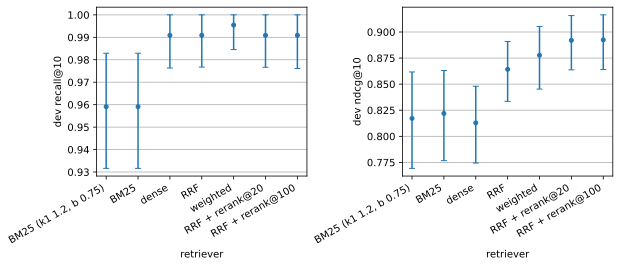

In [21]:
R0, R1 = (f'RRF + rerank@{n}' for n in RR_DEPTHS)
ORDER = ['BM25 (k1 1.2, b 0.75)', 'BM25', 'dense', 'RRF', 'weighted', R0, R1]
M = {n: d2l.retrieval_metrics(RANKED[n], GOLD) for n in ORDER}
KS = ('recall@1', 'recall@5', 'recall@10', 'mrr@10', 'ndcg@10')
TAB = pd.DataFrame({n: {k: boot(M[n][k]) for k in KS} | {
    'recall@100': f'{M[n]["recall@100"].mean():.3f}',
    'ms': f'{MS[n]:.1f}'} for n in ORDER}).T
print(TAB[list(KS[:3])].to_string())  # two tables: the page's width
print(TAB[list(KS[3:]) + ['recall@100', 'ms']].to_string())
better = max(('BM25', 'dense'), key=lambda n: M[n]['recall@10'].mean())
DELTAS = [  # (row, against, metric, questions)
    ('BM25', 'BM25 (k1 1.2, b 0.75)', 'recall@10', 'all'),
    *[('dense', 'BM25', k, sub) for k in ('recall@10', 'ndcg@10')
      for sub in ('all', 'identifier', 'other')],
    *[('RRF', n, k, 'all') for n in ('BM25', 'dense')
      for k in ('recall@10', 'ndcg@10')],
    ('weighted', 'RRF', 'recall@10', 'all'),
    ('weighted', 'RRF', 'ndcg@10', 'all'),
    (R0, 'RRF', 'ndcg@10', 'all'), (R0, 'RRF', 'recall@10', 'all'),
    (R1, R0, 'ndcg@10', 'all'), (R1, R0, 'recall@10', 'all')]
rows = []
for a, b, k, sub in DELTAS:
    keep = {'all': IDENT | ~IDENT, 'identifier': IDENT, 'other': ~IDENT}[sub]
    rows.append({'difference': f'{a} - {b}', 'metric': k,
                 'questions': f'{sub} ({keep.sum()})', 'mean [95% CI]': boot(
                     M[a][k][keep], M[b][k][keep], CLUSTER[keep])})
D = pd.DataFrame(rows)
col = D['mean [95% CI]']  # the sign-flip note goes below the table
D['mean [95% CI]'] = col.str.replace(r' \(.*\)$', '', regex=True)
print(D.to_string(index=False))
for line in [f'  {d}, {m}, {q}: {n}' for d, m, q, n in zip(
        D.difference, D.metric, D.questions,
        col.str.extract(r' \((.*)\)$')[0]) if isinstance(n, str)]:
    print(line)
print(f'the better single retriever on dev is {better}')
print('* fewer than 100 questions or 30 documents: the interval is '
      'unreliable; with fewer\n  than 30 documents it resamples questions, '
      'ignores their correlation within a\n  document and is likely too '
      "narrow; the sign-flip p over the documents' mean\n  differences "
      'decides')
d2l.use_svg_display()
_, axes = d2l.plt.subplots(1, 2, figsize=(8.5, 3.6), layout='constrained')
for ax, k in zip(axes, ('recall@10', 'ndcg@10')):
    cis = [d2l.bootstrap_ci(M[n][k], cluster=CLUSTER) for n in ORDER]
    d2l.plot_intervals(ORDER, {k: ([r.mean for r in cis], [
        r.ci[0] for r in cis], [r.ci[1] for r in cis])}, 'retriever',
                       f'dev {k}', axes=ax)

<!-- d2l:prose id=retrieval-md-19 fw=all -->

Over all questions the embedder finds a relevant chunk among the first ten
for about 3 points more of the questions than BM25, an interval from 0.5 to
6 points, and the two rank equally well: their nDCG@10 differ by 0.01,
within noise. The split shows where each is stronger. On the other
questions the embedder finds 6 points more, an interval that excludes zero.
On the identifier questions the two find a relevant chunk about equally
often (BM25 two questions more), but BM25 ranks it higher, by about 0.09 in
nDCG@10, a difference the sign-flip test rejects as chance (p 0.007). The
opening cell showed why in a single question: the embedder places the
passage about a function among other passages on the same subject, while
the function's exact name lifts it to the top for BM25.

Fusion keeps the embedder's recall and ranks better than either list. It
beats the embedder by about 0.05 in nDCG@10 and BM25 by 0.04, both
intervals excluding zero, and it puts a relevant chunk first for 80% of
the questions, against 76% for BM25 and 70% for the embedder. Reranking the
first 20 improves the ranking again. It adds about 0.03 to fusion's
nDCG@10, an interval from 0.005 to 0.05 and a fifth of the remaining
distance to a perfect ranking, and lifts that 80% to 84%. The plot shows
the same: the retrievers differ little in Recall@10 (left) and more in
nDCG@10 (right).

Two changes gained nothing, and both had no room to gain. Tuning BM25 did
not change dev Recall@10 on a single question, as the flat grid predicted.
Reranking
100 chunks instead of 20 did not move nDCG@10 and took five times as long,
because for all but one question the first 20 fused chunks already hold a
relevant one.

"Dense retrieval beats BM25" is a claim about a corpus, a question set and a
model. Our questions were drafted from the book's passages and reuse their
rare words (that section), which makes counting words a
very high floor. The BEIR benchmark [@Thakur.Reimers.Ruckle.ea.2021] found
dense retrievers trained on one collection often below BM25 on another. The
advice that survives both is to keep the word index and fuse instead of
choosing: running both and fusing them costs about a millisecond per
question and covers both kinds of failure.

## Approximate Nearest Neighbors

For the book, the flat scan needs no help, but its cost grows with the
collection. The synthetic matrix of 131,072 vectors already took 0.33 ms per
question on the GPU. A hundred million web passages, at 1,024 coordinates
of two bytes each, hold about 200 GB of vectors; scanning them would take
about a quarter of a second per question, if they fitted on the card at
all. We build two approximate indexes from scratch, use a third through
Faiss, a C++ library of vector indexes with a Python interface, and measure
all three on a larger collection.

### Inverted Files

The first index is the word index again, with clusters in place of words.
k-means cuts the space into $n_{\text{list}}$ cells, each holding the vectors
nearest to one centroid, and the vectors are stored grouped by cell. A
question finds its $n_{\text{probe}}$ nearest centroids and scans only their
cells. With cells of equal size it compares

$$
n_{\text{list}} + n_{\text{probe}}\, \frac{N}{n_{\text{list}}}
$$

vectors instead of $N$: the centroids, then the probed cells. What the index
gives up is exactness: a neighbor just across the border of an unprobed
cell is never seen (right of the figure). `kmeans` alternately
assigns each vector to its nearest centroid and moves each centroid to the
mean of its vectors (Lloyd's algorithm), starting from k-means++ seeds,
which spread the first centroids apart. `IVFIndex` stores the vectors cell
by cell and scans the probed cells exactly.

In [22]:

def kmeans(X, n_clusters, n_iter=20, seed=0):
    """Lloyd's k-means of the rows of X from a seeded k-means++ start:
    (centroids (n_clusters, d), assign (N,)) as tensors on X's device,
    assign naming each row's nearest centroid. A cluster that loses all
    its rows keeps its centroid."""
    X = torch.as_tensor(X, dtype=torch.float32)
    x2, gen = (X ** 2).sum(1), torch.Generator().manual_seed(seed)

    def nearest(C):  # ||x||^2 is the same for every centroid: left out
        c2 = (C ** 2).sum(1)
        return torch.cat([(c2 - 2 * Xb @ C.T).argmin(1)
                          for Xb in X.split(8192)])

    def pick(d2):  # a row drawn with probability proportional to d2
        w = d2.double().cpu().clamp(min=0)
        if w.sum() == 0:
            return torch.randint(len(X), (1,), generator=gen).item()
        return torch.multinomial(w, 1, generator=gen).item()

    C = [X[pick(torch.ones(len(X)))]]
    d2 = x2 - 2 * X @ C[0] + C[0] @ C[0]
    for _ in range(1, n_clusters):  # k-means++: far rows are likelier
        C.append(X[pick(d2)])
        d2 = torch.minimum(d2, x2 - 2 * X @ C[-1] + C[-1] @ C[-1])
    C = torch.stack(C)
    for _ in range(n_iter):
        assign = nearest(C)
        counts = torch.bincount(assign, minlength=n_clusters)
        sums = torch.zeros_like(C).index_add_(0, assign, X)
        keep = counts > 0
        C[keep] = sums[keep] / counts[keep, None]
    return C, nearest(C)


class IVFIndex:
    """Inverted file index: the k-means cells of the training vectors; a
    query scans the vectors of its nprobe nearest cells exactly, by
    squared Euclidean distance (for unit vectors, the cosine order)."""
    def __init__(self, nlist, nprobe=1):
        self.nlist, self.nprobe = nlist, nprobe

    def train(self, X, n_iter=20, seed=0):
        self.centroids = d2l.kmeans(X, self.nlist, n_iter, seed)[0]

    def _cells(self, X, n):
        """The n nearest cells of each row of X."""
        d = (self.centroids ** 2).sum(1) - 2 * X @ self.centroids.T
        return d.topk(n, dim=1, largest=False).indices

    def add(self, X):
        """Store the rows of X (ids 0, 1, ...) grouped by cell."""
        X = torch.as_tensor(X, dtype=torch.float32)
        cell = self._cells(X, 1)[:, 0]
        self.ids = torch.argsort(cell, stable=True)
        self.X = X[self.ids]
        sizes = torch.bincount(cell, minlength=self.nlist)
        self.start = torch.cat([torch.zeros(1, dtype=torch.long),
                                sizes.cumsum(0)])  # cell c: start[c:c + 2]

    def search(self, Q, k):
        """(distances, ids) of the k nearest stored rows per query, nearest
        first, among the probed cells; id -1 where they hold fewer."""
        Q = torch.as_tensor(Q, dtype=torch.float32)
        D = torch.full((len(Q), k), torch.inf)
        I = torch.full((len(Q), k), -1, dtype=torch.long)
        for j, cells in enumerate(self._cells(Q, self.nprobe).tolist()):
            rows = torch.cat([torch.arange(self.start[c], self.start[c + 1])
                              for c in cells])
            top = ((self.X[rows] - Q[j]) ** 2).sum(1).topk(
                min(k, len(rows)), largest=False)
            n = len(top.values)
            D[j, :n], I[j, :n] = top.values, self.ids[rows[top.indices]]
        return D, I

<!-- d2l:prose id=retrieval-md-20 fw=all -->

### Product Quantization

An inverted file still stores every vector in full. Faiss's CPU indexes
hold float32, twice the bytes of our stored float16 vectors, so a vector
takes 4 KB; byte counts from here on are float32.
@Jegou.Douze.Schmid.2011 store
a short code instead and compute distances from the code without decoding
it. This is the cleverest idea of the section, and the step worth
understanding is how a distance can be read off a code.

Split $\mathbf{x} \in \mathbb{R}^m$ into $M$ blocks
$\mathbf{x}^{(1)}, \ldots, \mathbf{x}^{(M)}$ of $m/M$ coordinates each. For
each position $j$, learn a codebook of $K$ centroids
$\mathbf{c}_{j,0}, \ldots, \mathbf{c}_{j,K-1}$ by k-means on the blocks at
that position, and replace $\mathbf{x}^{(j)}$ by the index $i_j$ of its
nearest centroid. The code $(i_1, \ldots, i_M)$ takes $M \log_2 K$ bits, one
byte per block at $K = 256$, and the reconstruction $\hat{\mathbf{x}}$
concatenates the chosen centroids. $M$ codebooks of $K$ entries name $K^M$
reconstructions; this product of small codebooks gives the method its name.

The smallest case can be done by hand (left of the figure).
Take $m = 4$, $M = 2$ and $K = 2$,
with codebooks $\{(1, 0), (0, 1)\}$ for the first two coordinates and
$\{(1, 1), (-1, 0)\}$ for the last two. For
$\mathbf{x} = (0.9, 0.2, -0.8, 0.1)$ the first block is nearest to $(1, 0)$
(squared distance 0.05 against 1.45) and the second to $(-1, 0)$ (0.05
against 4.05), so the code is $(0, 1)$ and $\hat{\mathbf{x}} = (1, 0, -1, 0)$.
Now take the question $\mathbf{y} = (1, 1, 0, 0)$. Its first block, $(1, 1)$,
lies at squared distance 1 from both centroids of the first codebook; its
second block, $(0, 0)$, at 2 and 1 from those of the second. With these four
numbers in a table $T$, the squared distance from $\mathbf{y}$ to the code is
$T_1[0] + T_2[1] = 1 + 1 = 2$, read off in two look-ups without decoding
anything. The exact squared distance to $\mathbf{x}$ is 1.30.

![Product quantization and the inverted file. Left: the hand case with $m = 4$, $M = 2$ and $K = 2$. Each block of $\mathbf{x}$ is replaced by the index of its nearest centroid (squared distances beside the centroids), so the code is $(0, 1)$. For the question $\mathbf{y}$, the table $T_j[i]$ holds the squared distance from each block of $\mathbf{y}$ to each centroid, and the distance to the code is the sum of the two entries the code selects. Right: k-means cuts the plane into $n_{\textrm{list}} = 8$ cells (centroids as diamonds); the question scans the points of its $n_{\textrm{probe}} = 2$ nearest cells (shaded) and misses its nearest point, which lies just across a border.](../img/mdl-lm-encoders-ivf-pq.svg)

The look-ups work in general, because a squared distance is a sum over
coordinates and therefore over blocks. For a question $\mathbf{y}$, kept
exact,

$$
\|\mathbf{y} - \hat{\mathbf{x}}\|^2 = \sum_{j=1}^{M} \big\|\mathbf{y}^{(j)} - \mathbf{c}_{j,i_j}\big\|^2 = \sum_{j=1}^{M} T_j[i_j].
$$

The table $T_j[i] = \|\mathbf{y}^{(j)} - \mathbf{c}_{j,i}\|^2$ has $MK$
entries and depends only on the question, so it is built once per question
with $Km$ multiply-adds, the cost of 256 exact distances at $K = 256$; after
that each code costs $M$ look-ups, whatever $m$ is. Only the stored vectors
are quantized, hence the name *asymmetric distance computation*. At
$m = 1{,}024$, $M = 64$ and $K = 256$ a code takes 64 bytes against 4,096 in
float32, plus 1 MiB of codebooks for the whole collection.

How wrong is the distance? Write $\mathbf{e} = \mathbf{x} - \hat{\mathbf{x}}$
for the quantization error. The triangle inequality bounds the error for
every question at once,

$$
\big|\, \|\mathbf{y} - \mathbf{x}\| - \|\mathbf{y} - \hat{\mathbf{x}}\| \,\big| \le \|\mathbf{e}\|,
$$

so a vector that is quantized well is ranked well. In the hand case the
error of the distance, $|\sqrt{1.30} - \sqrt{2}| = 0.27$, stays below
$\|\mathbf{e}\| = \sqrt{0.10} = 0.32$. Like the distance, $\|\mathbf{e}\|^2$
is a sum over blocks, so the mean squared error of the quantizer is the sum
of the distortions of its $M$ codebooks, each minimized by its own k-means.

On average we can say more. Substituting
$\mathbf{y} - \mathbf{x} = (\mathbf{y} - \hat{\mathbf{x}}) - \mathbf{e}$ gives

$$
\|\mathbf{y} - \mathbf{x}\|^2 = \|\mathbf{y} - \hat{\mathbf{x}}\|^2 - 2\,(\mathbf{y} - \hat{\mathbf{x}})^\top \mathbf{e} + \|\mathbf{e}\|^2.
$$

At convergence each centroid is the mean of its cell, so each block of
$\mathbf{e}$ has mean zero in every cell of its codebook. Two things follow.
Each block of $\hat{\mathbf{x}}$ is constant within a cell, so
$\hat{\mathbf{x}}^\top \mathbf{e}$ averages to zero; and for a question
independent of $\mathbf{x}$, so does $\mathbf{y}^\top \mathbf{e}$. The middle
term therefore vanishes on average. Averaged over the stored vectors, the
asymmetric distance is smaller than the true squared distance by the mean
distortion, and by the same amount for every question. A single pair can go
either way: the hand case overestimates. A shift that is the same for every
vector would leave the ranking alone. What reorders neighbors is the part
that changes from vector to vector: the cross term, which averages to zero
but not for each vector, and $\|\mathbf{e}\|^2$. The bound limits both
together: two neighbors closer together than their quantization errors can
swap places.

A product quantizer compresses each vector as a low-rank approximation does
(that section), but where a rank-$r$ approximation projects
every vector onto one shared subspace, the quantizer picks for each block one
of finitely many points: its reconstructions form a grid, not a subspace.
`ProductQuantizer` fits one codebook per block and stores each index in a
byte. Its arguments follow Faiss: `m` is the number of blocks, our $M$, and
`nbits` is $\log_2 K$.

In [23]:

class ProductQuantizer:
    """Product quantization: a vector of d coordinates is cut into m
    sub-vectors, each replaced by the index of the nearest of 2^nbits
    centroids of its own k-means codebook (one byte per sub-vector here).
    A query's squared distances to all codes are sums of m entries of a
    table computed once per query: the asymmetric distance."""
    def __init__(self, m, nbits=8):
        if not 1 <= nbits <= 8:
            raise ValueError('codes are stored as one byte per sub-vector')
        self.m, self.nbits = m, nbits

    def _split(self, X):  # (..., d) -> (..., m, d / m)
        X = torch.as_tensor(X, dtype=torch.float32)
        if X.shape[-1] % self.m:
            raise ValueError(f'{X.shape[-1]} coordinates in {self.m} parts')
        return X.reshape(*X.shape[:-1], self.m, X.shape[-1] // self.m)

    def fit(self, X, n_iter=20, seed=0):
        S = self._split(X)
        self.codebooks = torch.stack([d2l.kmeans(  # (m, 2^nbits, d / m)
            S[:, j], 2 ** self.nbits, n_iter, seed)[0] for j in range(self.m)])
        return self

    def encode(self, X):
        """Codes (N, m), uint8: the nearest centroid of each sub-vector."""
        S, c2 = self._split(X), (self.codebooks ** 2).sum(-1)
        return torch.cat([(c2 - 2 * torch.einsum(
            'nmd,mkd->nmk', block, self.codebooks)).argmin(-1)
                          for block in S.split(1024)]).to(torch.uint8)

    def decode(self, codes):
        """The reconstructions x-hat (N, d) of codes."""
        codes = torch.as_tensor(codes).long()
        return self.codebooks[torch.arange(self.m), codes].flatten(1)

    def adc_table(self, q):
        """(m, 2^nbits) squared distances of q's sub-vectors to the
        centroids."""
        return ((self._split(q)[:, None, :] - self.codebooks) ** 2).sum(-1)

    def adc_search(self, q, codes, k):
        """(distances, ids) of the k codes nearest to the query q, or to
        each row of q, by m table look-ups per code."""
        q = torch.as_tensor(q, dtype=torch.float32)
        codes = torch.as_tensor(codes).long()  # a no-op if already int64
        if q.ndim == 2:
            out = [self.adc_search(row, codes, k) for row in q]
            return tuple(torch.stack(t) for t in zip(*out))
        d = self.adc_table(q)[torch.arange(self.m), codes].sum(1)
        top = d.topk(min(k, len(d)), largest=False)
        return top.values, top.indices

<!-- d2l:prose id=retrieval-md-21 fw=all -->

The cell checks the hand case, then five claims on 20,000 points from a
mixture of 16 Gaussians in 64 dimensions, synthetic data whose structure we
know and small enough to check pair by pair, with $M = 8$ and $K = 256$:
(1) the table gives the distance to the reconstruction; (2) the bound
holds; (3) $\mathbf{y}^\top \mathbf{e}$ and $\hat{\mathbf{x}}^\top \mathbf{e}$
average to zero; (4) Faiss, given
our codebooks, assigns our codes; (5) the distortion is the sum of the
blocks' distortions.

In [24]:
pq = d2l.ProductQuantizer(2, nbits=1)  # m = 4, M = 2, K = 2, set by hand
pq.codebooks = torch.tensor([[[1., 0.], [0., 1.]], [[1., 1.], [-1., 0.]]])
x, y = torch.tensor([[0.9, 0.2, -0.8, 0.1]]), torch.tensor([1., 1., 0., 0.])
code = pq.encode(x)
x_hat, table = pq.decode(code), pq.adc_table(y)
adc_hand = table[torch.arange(2), code[0].long()].sum()  # two look-ups
print(f'code {code[0].tolist()}, x_hat {x_hat[0].tolist()}')
print(pd.DataFrame(table.numpy(), index=['j = 1', 'j = 2'],
                   columns=['i = 0', 'i = 1']))
print(f'ADC {adc_hand:.2f}; |y - x_hat|^2 {((y - x_hat) ** 2).sum():.2f}; '
      f'|y - x|^2 {((y - x) ** 2).sum():.2f}; |d - d_A| '
      f'{abs((y - x).norm() - (y - x_hat).norm()):.3f} <= |x - x_hat| '
      f'{(x - x_hat).norm():.3f}')
rng = np.random.default_rng(0)  # 16 Gaussians in R^64
mu = 2 * rng.standard_normal((16, 64))
draw = lambda n: torch.tensor(mu[rng.integers(16, size=n)]
                              + rng.standard_normal((n, 64)))
Xg, Yg = draw(20_000).float(), draw(1_000).float()
pq = d2l.ProductQuantizer(8, nbits=8).fit(Xg)
codes = pq.encode(Xg)
Xh = pq.decode(codes)
adc = torch.stack([pq.adc_table(y)[torch.arange(8), codes.long()].sum(1)
                   for y in Yg[:20]]).double()  # (20 queries, all codes)
exact = ((Yg[:20, None].double() - Xh.double()) ** 2).sum(-1)
print(f'(1) table against reconstruction distances: largest relative '
      f'difference {((adc - exact).abs() / exact).max():.1e}')
qi, xi = rng.integers(1_000, size=10**5), rng.integers(20_000, size=10**5)
Y, X0, X1 = Yg.double()[qi], Xg.double()[xi], Xh.double()[xi]
gap = ((Y - X0).norm(dim=1) - (Y - X1).norm(dim=1)).abs()
print(f'(2) |d - d_A| <= |x - x_hat| on {len(qi):,} pairs: '
      f'{(gap <= (X0 - X1).norm(dim=1) + 1e-9).float().mean():.4f}')
se = lambda v: v.std() / len(v) ** 0.5  # standard error of a mean
cross, own = (Y * (X0 - X1)).sum(1), (X1 * (X0 - X1)).sum(1)
print(f'(3) mean (standard error) of y^T e {cross.mean():.4f} '
      f'({se(cross):.4f}), of x_hat^T e {own.mean():.4f} ({se(own):.4f})')
fpq = faiss.IndexPQ(64, 8, 8)
faiss.copy_array_to_vector(pq.codebooks.numpy().ravel(), fpq.pq.centroids)
fpq.is_trained = True
same = (fpq.sa_encode(Xg.numpy()) == codes.numpy()).all(1).mean()
print(f'(4) Faiss codes with our codebooks equal ours for {same:.4f} of '
      f'the vectors')
err2 = ((Xg - Xh) ** 2).double()  # (N, 64): squared error per coordinate
blocks = err2.reshape(-1, 8, 8).sum(-1).mean(0)  # each block's distortion
print(f'(5) mean |e|^2 {err2.sum(1).mean():.3f} = sum of the 8 blocks\' '
      f'distortions {blocks.sum():.3f}\n    ('
      + ', '.join(f'{b:.2f}' for b in blocks) + ')')
assert abs(adc_hand - 2.0) < 1e-6
assert ((adc - exact).abs() / exact).max() < 1e-5
assert bool((gap <= (X0 - X1).norm(dim=1) + 1e-9).all())
assert abs(cross.mean()) < 3 * se(cross) and abs(own.mean()) < 3 * se(own)
assert same >= 0.999
assert abs(err2.sum(1).mean() - blocks.sum()) < 1e-9 * blocks.sum()

code [0, 1], x_hat [1.0, 0.0, -1.0, 0.0]
       i = 0  i = 1
j = 1    1.0    1.0
j = 2    2.0    1.0
ADC 2.00; |y - x_hat|^2 2.00; |y - x|^2 1.30; |d - d_A| 0.274 <= |x - x_hat| 0.316


(1) table against reconstruction distances: largest relative difference 2.3e-07
(2) |d - d_A| <= |x - x_hat| on 100,000 pairs: 1.0000


(3) mean (standard error) of y^T e -0.0434 (0.0417), of x_hat^T e 0.0214 (0.0384)
(4) Faiss codes with our codebooks equal ours for 1.0000 of the vectors
(5) mean |e|^2 36.056 = sum of the 8 blocks' distortions 36.056
    (4.50, 4.54, 4.53, 4.50, 4.50, 4.52, 4.50, 4.48)


<!-- d2l:prose id=retrieval-md-22 fw=all -->

All five hold. Table and reconstruction distances agree to
$2 \times 10^{-7}$ relative, the bound holds on every pair, and the means
of $\mathbf{y}^\top \mathbf{e}$ and $\hat{\mathbf{x}}^\top \mathbf{e}$ lie
within about one standard error of zero, where noise alone would put them. Faiss assigns our codes to every vector. The mean
squared error, about 36, is the sum of eight block distortions of about
4.5; set against 64, the mean squared distance of a point from its own
Gaussian's center, it says that the codes keep the cluster and lose much of
the position within it.

The two indexes combine. *IVF-PQ* stores, in each cell of an inverted file,
the codes of its vectors' offsets from the cell's centroid. A question
probes $n_{\text{probe}}$ cells as before and scores the codes of each with a
table built for its own offset from that cell's centroid. Each vector then
costs its code and an 8-byte id; the coarse centroids and the codebooks are
shared by the whole collection. The offsets are shorter than the vectors,
so the same codebooks quantize them with a smaller error. There is a cost,
though, and it is easy to overlook. Two close vectors often share the code
of a block, and then they share its reconstruction: in that block the
comparison between them errs by no more than their own small difference.
Plain codes give close vectors this sharing wherever they lie. Offsets give
it only to neighbors in the same cell; two neighbors on either side of a
border are coded from different centroids, and their errors are
independent. Which effect wins depends on how many cells a question's
neighbors are spread over, and we will measure both.

### Navigable Small-World Graphs

The third index needs no cells. Link every vector to a few near neighbors
and search by walking: start somewhere, move to whichever neighbor is closest
to the question, and stop when none is closer. On a well-built graph a few
dozen steps cross millions of vectors, as a short chain of acquaintances
connects two strangers. The walk can also stop too early, at a vector that
is closer to the question than all of its own neighbors but is not the
nearest overall.

A walk that starts far from the question needs many short steps.
*Hierarchical navigable small-world graphs* (HNSW) [@Malkov.Yashunin.2020] therefore add layers. Every vector is on the
bottom layer, and a random subset that shrinks geometrically is also on the
layers above, where the links are long. A search crosses the collection on
the top layer and refines its answer at the bottom.

Three knobs set the graph. Each vector keeps up to 32 links per layer here
(Faiss's parameter `M`), and up to twice that at the bottom. The builder
keeps $\mathit{efConstruction}$ candidates while choosing links. A search
keeps not one current vector at the bottom layer but a list of
$\mathit{efSearch}$ candidates, so it can step back from a dead end; a
longer list finds more of the true neighbors and takes longer. The first
two knobs can be looked up when needed; $\mathit{efSearch}$ is the one a
user turns, at search time and without rebuilding. The links are 4-byte
ids, so 64 of them add 256 bytes per vector at the bottom layer, a little
more with the layers above, next to the 4,096 bytes of the vector itself. A graph needs
about as much memory as a flat index.

### Measuring the Indexes

To see an index at work we need more vectors than the book has. The stress
collection adds to the book's chunk vectors about 62,500 Wikipedia passages
from Natural Questions, the pairs of search questions and passages that
that section trained on; they come from the pairs its
contrastive training did not use. The same model embeds them, and 1,000 of
their questions serve as timed queries. The off-topic passages enlarge the
haystack without making the book's questions harder: the collection tests
whether an index finds the exact nearest neighbors, not how hard retrieval
is.

In [25]:
if 'ret-stress-emb' in RERUN:
    nq = pd.read_parquet(d2l.download_keyed('nq-pairs'))
    rows = np.random.default_rng(0).permutation(len(nq))[20_000:]
    passages = list(dict.fromkeys(nq.answer.iloc[rows]))  # distinct, in order
    at = {p: j for j, p in enumerate(passages)}
    pick = rows[np.random.default_rng(0).choice(len(rows), N_NQ_QUERIES,
                                                replace=False)]
    encoder = d2l.load_encoder(EMB, padding_side=QUERY['padding_side'],
                               dtype=DTYPE)
    P = d2l.embed_texts(*encoder, passages, pooling=QUERY['pooling'],
                        max_len=512)
    Q = embed_queries(encoder, nq['query'].iloc[pick].tolist(), NQ_TASK)
    del encoder
    d2l.lm_free()
    d2l.lm_save_rerun(ARTIFACTS['ret-stress-emb'][1], lambda path: np.savez(
        path, X=np.concatenate([X.cpu().numpy(), P.half().numpy()]),
        ids=np.array(FULL.ids + [f'nq:{j}' for j in range(len(passages))]),
        Q=Q.half().numpy(), q_gold=np.array([len(FULL) + at[p] for p in
                                             nq.answer.iloc[pick]]),
        config=json.dumps(CONFIG['ret-stress-emb'])))
with np.load(result_path('ret-stress-emb')) as Z:
    assert json.loads(str(Z['config'])) == json.loads(json.dumps(
        CONFIG['ret-stress-emb'])), 'D2L_RERUN=ret-stress-emb'
    XS, STRESS_IDS = Z['X'][:STRESS_N].astype(np.float32), Z['ids'][:STRESS_N]
    QS = Z['Q'].astype(np.float32)
    book_diff = np.abs(Z['X'][:len(FULL)].astype(np.float32)
                       - X.float().cpu().numpy()).max()
assert book_diff == 0, 'the stress file holds other book chunk vectors'
QD = Q_DEV.numpy()
print(f'{len(XS):,} vectors of {XS.shape[1]} coordinates '
      f'({XS.nbytes / 2**20:,.0f} MiB in float32), '
      f'{np.mean(np.char.startswith(STRESS_IDS, "sec512:")):.3f} of them '
      f'book chunks;\n  {len(QS):,} timed questions; book vectors differ from '
      f'the chunk vectors by at most {book_diff:.1e}')

67,853 vectors of 1024 coordinates (265 MiB in float32), 0.078 of them book chunks;
  1,000 timed questions; book vectors differ from the chunk vectors by at most 0.0e+00


<!-- d2l:prose id=retrieval-md-23 fw=all -->

The collection holds 67,853 vectors, 265 MiB in float32. For every index
along its knob, the next cell measures two kinds of recall.
*Recall against exact search* is the share of the exact ten nearest
neighbors that the index returns for the 1,000 timed questions; it
measures the index. *Task recall* is the Recall@10 of the 220 dev questions
searched among all 67,853 vectors; it measures what a reader of the results
sees. The cell also records the median (p50) and 95th-percentile latency of
one-question searches on one CPU thread, and the bytes per vector.

The inverted files have 1,024 cells, close to $\sqrt{16 N}$, the count that
minimizes the vectors compared at 16 probes (an exercise derives it). IVF-PQ
stores 64-byte codes, built with three k-means seeds, and 32-byte ones. The
rows marked "ours" give the recall of `IVFIndex` and of `ProductQuantizer`
scanning all codes; their latencies are those of plain PyTorch code, and
for the quantizer of a scan of every code, not of the methods.

In [26]:
d = XS.shape[1]
exact = faiss.IndexFlatL2(d)
exact.add(XS)
TRUE = exact.search(QS, 10)[1]  # the exact ten nearest of each question
ROWS = []

def threads(n):
    faiss.omp_set_num_threads(n)
    torch.set_num_threads(n)

def build(key, data, seed=0):
    """A Faiss index from its factory string, trained and filled with data
    (k-means seeded), and its build seconds."""
    threads(BUILD_THREADS)
    t0 = time.perf_counter()
    index = faiss.index_factory(data.shape[1], key)
    if key.startswith('IVF'):
        faiss.extract_index_ivf(index).cp.seed = seed
        if 'PQ' in key:
            index.pq.cp.seed = seed
    if key.startswith('HNSW'):
        index.hnsw.efConstruction = EF_CONSTRUCTION
    index.train(data)
    index.add(data)
    return index, time.perf_counter() - t0

def latency(search, Q):
    """p50 and p95 (ms) of one-question searches on one thread, after
    warm-up searches with the dev questions."""
    threads(1)
    for q in QD[:N_WARM]:
        search(q[None])
    t = []
    for q in Q:
        t0 = time.perf_counter()
        search(q[None])
        t.append(time.perf_counter() - t0)
    threads(BUILD_THREADS)
    return np.median(t) * 1e3, np.percentile(t, 95) * 1e3

def overlap(found, true):
    """Recall@10 against exact search: the share of the true ten found."""
    return np.mean([len(set(a) & set(b)) / 10 for a, b in zip(found, true)])

def record(family, knob, search, code_bytes, index_bytes, build_s, seed=0):
    """Recall against exact search, dev Recall@10, and one-thread latency."""
    threads(BUILD_THREADS)
    task = d2l.retrieval_metrics([[STRESS_IDS[i] for i in r if i >= 0]
                                  for r in search(QD)[1]], GOLD, ks=(10,))
    p50, p95 = latency(search, QS)
    ROWS.append(dict(family=family, knob=knob, seed=seed,
                     recall=overlap(search(QS)[1], TRUE),
                     task_recall=task['recall@10'].mean(), p50=p50, p95=p95,
                     code_bytes=code_bytes, index_bytes=index_bytes,
                     build_s=build_s))

def size(index):
    return len(faiss.serialize_index(index)) / index.ntotal

index, t = build('Flat', XS)
record('flat', '', lambda Q: index.search(Q, 10), 4 * d, size(index), t)
for fam, key, code in [('IVF-Flat', f'IVF{NLIST},Flat', 4 * d)] + [
        (f'IVF-PQ{M_}', f'IVF{NLIST},PQ{M_}', M_) for M_ in PQ_MS]:
    for seed in (PQ_SEEDS if fam == f'IVF-PQ{PQ_MS[0]}' else PQ_SEEDS[:1]):
        index, t = build(key, XS, seed)
        for p in (NPROBES if seed == PQ_SEEDS[0] else (16,)):
            faiss.extract_index_ivf(index).nprobe = p
            record(fam, f'nprobe {p}', lambda Q: index.search(Q, 10), code,
                   size(index), t, seed)
if STRESS_N is None:  # the reduced path builds no graph
    index, t = build(f'HNSW{HNSW_M}', XS)
    for ef in EF_SEARCHES:
        index.hnsw.efSearch = ef
        record(f'HNSW{HNSW_M}', f'efSearch {ef}',
               lambda Q: index.search(Q, 10), 4 * d, size(index), t)
threads(BUILD_THREADS)
t0 = time.perf_counter()
ivf = d2l.IVFIndex(NLIST, nprobe=16)
ivf.train(XS)
ivf.add(XS)
record('IVF-Flat (ours)', 'nprobe 16', lambda Q: [
    a.numpy() for a in ivf.search(Q, 10)], 4 * d, (ivf.X.numel() * 4 + len(
        ivf.ids) * 8 + ivf.centroids.numel() * 4) / len(XS),
       time.perf_counter() - t0)
t0 = time.perf_counter()
pq = d2l.ProductQuantizer(PQ_MS[0]).fit(XS)
codes = pq.encode(XS)  # one byte per sub-vector
idx = codes.long()  # the table look-ups take int64: converted once
record(f'PQ{PQ_MS[0]} (ours)', 'all codes', lambda Q: [
    a.numpy() for a in pq.adc_search(Q, idx, 10)], PQ_MS[0], (
        codes.numel() + pq.codebooks.numel() * 4) / len(XS),
       time.perf_counter() - t0)
if GPU:  # every question at once: a batched point, not a batch-1 latency
    XG = torch.from_numpy(XS).cuda()
    QG = torch.from_numpy(QS).cuda()
    secs = scan_seconds(QG, XG, reps=20)
    found = (QG @ XG.T).topk(10, dim=1).indices.cpu().numpy()
    ROWS.append(dict(family='flat, GPU, batched', knob=f'{len(QS)} at once',
                     seed=0, recall=overlap(found, TRUE),
                     p50=secs / len(QS) * 1e3, code_bytes=4 * d))
    del XG, QG
TABLE = pd.DataFrame(ROWS)
show_machine(machine())
print(TABLE.round({'recall': 4, 'task_recall': 4, 'p50': 4, 'p95': 4,
                   'index_bytes': 1, 'build_s': 1}).rename(columns={
    'task_recall': 'task rec.', 'code_bytes': 'code B',
    'index_bytes': 'index B', 'build_s': 'build s'}).to_string(index=False))
seeds = TABLE[(TABLE.family == f'IVF-PQ{PQ_MS[0]}') & (TABLE.knob ==
                                                        'nprobe 16')]
print(f'IVF-PQ{PQ_MS[0]}, nprobe 16, k-means seeds {list(seeds.seed)}: '
      f'recall {seeds.recall.min():.3f} to {seeds.recall.max():.3f}')
if 'ret-ann' in RERUN:
    write_result('ret-ann', rows=json.loads(TABLE.to_json(orient='records')))
reg = read_result('ret-ann', strict=False)
if reg is None:  # e.g. the reduced path, STRESS_N set
    print(f'the stored table was made with other settings than these '
          f'(N = {len(XS):,}, {NLIST} cells): no comparison')
else:
    reg = pd.DataFrame(reg['rows'])
    both = TABLE.merge(reg, on=['family', 'knob', 'seed'],
                       suffixes=('', '_reg'))
    both['recall_diff'] = (both.recall - both.recall_reg).abs()
    both['p50_ratio'] = both.p50 / both.p50_reg
    print(both.groupby('family', sort=False).agg(
        largest_recall_difference=('recall_diff', 'max'),
        median_p50_live_over_stored=('p50_ratio', 'median')).round(3))

AMD EPYC 7502 32-Core Processor, 64 cores, load 17.1; threads: torch 8, Faiss 8
GPU: NVIDIA GeForce RTX 4090, 1.3 of 24 GiB in use
            family         knob  seed  recall  task rec.     p50     p95  code B  index B  build s
              flat                  0  1.0000     0.9909 15.4441 20.4877    4096   4096.0      0.2
          IVF-Flat     nprobe 1     0  0.4646     0.7000  0.1497  0.1715    4096   4165.9      3.6
          IVF-Flat     nprobe 2     0  0.5962     0.8000  0.1686  0.1962    4096   4165.9      3.6
          IVF-Flat     nprobe 4     0  0.7012     0.8864  0.2071  0.2478    4096   4165.9      3.6
          IVF-Flat     nprobe 8     0  0.7777     0.9455  0.2811  0.3440    4096   4165.9      3.6
          IVF-Flat    nprobe 16     0  0.8459     0.9682  0.4263  0.5312    4096   4165.9      3.6
          IVF-Flat    nprobe 32     0  0.8985     0.9818  0.7878  0.9505    4096   4165.9      3.6
          IVF-Flat    nprobe 64     0  0.9420     0.9864  1.5003  1.7028    4

<!-- d2l:prose id=retrieval-md-24 fw=all -->

The inverted file does what the count predicts. At 16 probes it compares
about $1{,}024 + 16 \times 66 \approx 2{,}100$ vectors instead of 67,853, 33
times fewer, and runs about 35 times faster than the flat scan, about
0.4 ms against 16 ms. It loses recall: it returns 0.85 of the exact
neighbors at 16 probes, our `IVFIndex` as much as Faiss's, and 0.94 at 64.
The stored table agrees with this run, with the same recalls and latencies
within about 10%.

Product quantization trades recall for memory. IVF-PQ stores 149 bytes per
vector: the 64-byte code, the 8-byte id and, spread over this collection,
62 bytes of coarse centroids and 15 of codebooks. That is 27 times less than
the flat index, but recall against exact search stalls near 0.6: 0.59 to
0.60 at 16 probes across three k-means seeds, and only 0.62 at 64. Codes of
32 bytes lose clearly more (0.52 against about 0.6, well outside the spread
of the seeds). These are the swaps the bound allowed: neighbors that lie
closer together than their quantization errors. One row does not fit,
though. Our `ProductQuantizer`, which codes the vectors themselves and
scans every code, reaches 0.69, more than IVF-PQ at any number of probes,
although IVF-PQ codes the shorter offsets and should make the smaller
errors.

Is the probing to blame, or the coding? Sixty-four probes still stop at
0.62, which already points at the coding. The next cell settles it. It
builds IVF-PQ with 64-byte codes for 1 to 1,024 cells and probes every
cell, so that no neighbor is missed for lying in an unprobed cell; one
cell is plain product quantization. For each it prints recall against
exact search, the mean squared error $\|\mathbf{e}\|^2$ of the codes, and
the share of each question's ten exact neighbors that lie in the cell of
the nearest one.

In [27]:
cells_rows = []
for nlist in [1] + [n for n in (16, 64, 256) if n < NLIST] + [NLIST]:
    key = f'PQ{PQ_MS[0]}' if nlist == 1 else f'IVF{nlist},PQ{PQ_MS[0]}'
    index, t = build(key, XS)
    if nlist > 1:  # every cell probed: the coding is all that differs
        faiss.extract_index_ivf(index).nprobe = nlist
        cell = faiss.extract_index_ivf(index).quantizer.search(XS, 1)[1][:, 0]
    else:
        cell = np.zeros(len(XS), dtype=int)
    err = ((XS - index.sa_decode(index.sa_encode(XS))) ** 2).sum(1).mean()
    cells_rows.append({'cells': nlist, 'vectors per cell': len(XS) // nlist,
                       'recall': overlap(index.search(QS, 10)[1], TRUE),
                       'mean |e|^2': err, 'top 10 in the cell of the 1st':
                       (cell[TRUE] == cell[TRUE[:, :1]]).mean()})
print(f'PQ{PQ_MS[0]} codes; residual codes in every cell, all cells probed')
print(pd.DataFrame(cells_rows).round(3).to_string(index=False))

PQ64 codes; residual codes in every cell, all cells probed
 cells  vectors per cell  recall  mean |e|^2  top 10 in the cell of the 1st
     1             67853   0.703       0.414                          1.000
    16              4240   0.696       0.383                          0.676
    64              1060   0.680       0.359                          0.588
   256               265   0.654       0.331                          0.521
  1024                66   0.627       0.298                          0.489


<!-- d2l:prose id=retrieval-md-25 fw=all -->

The offsets keep their promise: as the cells shrink, the mean squared error
of the codes falls from 0.41 to 0.30. Recall moves the other way, from 0.70
with one cell to 0.63 with 1,024, although every cell is probed. The last
column explains it. With one cell, every pair of neighbors is coded the
same way, and two close vectors that share a block's code share its
reconstruction: in that block their comparison errs by no more than their
own small difference. At 1,024 cells only about half of a question's ten
exact neighbors lie in the cell of the nearest one. The other half are
coded against other centroids, and their errors become independent. A
smaller error helps little once it stops being shared. Probing
all 1,024 cells lifts recall only to 0.63, from 0.62 at 64 probes: what
IVF-PQ loses against plain codes on this collection is lost in the coding,
not in the probing.

Whatever the codes lose, the usual repair rescores the best hundred
candidates with exact vectors kept on disk. (The rescoring of binary
vectors in that section was a cheaper cousin: it used
the exact question but kept the passages at one bit.)

The graph wins at this size. HNSW returns 0.97 of the exact neighbors at
$\mathit{efSearch} = 32$ in about 0.3 ms, and 0.998 at 256 in under 2 ms, for
272 bytes per vector beyond the vector itself, nearly all of it links, and
about 15 s of building with eight threads.

Task recall drops far less, because it needs one relevant chunk among ten
where recall against exact search counts all ten neighbors. IVF-Flat at 16
probes misses 15% of the exact neighbors and loses only about 0.02 of task
recall. IVF-PQ64 misses 40% and loses between 0.05 and 0.09, depending on
the k-means seed. Recall against exact search measures the index, and task
recall what a user notices.

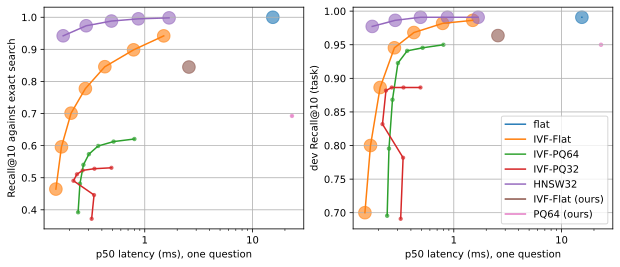

In [28]:
PLOT = TABLE[(TABLE.seed == 0) & ~TABLE.family.str.contains('batched')]
families = list(PLOT.family.unique())
_, axes = d2l.plt.subplots(1, 2, figsize=(8.5, 3.6), layout='constrained')
for ax, col, label in zip(axes, ('recall', 'task_recall'), (
        'Recall@10 against exact search', 'dev Recall@10 (task)')):
    lines = [PLOT[PLOT.family == f] for f in families]
    d2l.plot([t.p50.tolist() for t in lines], [t[col].tolist() for t in lines],
             'p50 latency (ms), one question', label, xscale='log',
             legend=families if col == 'task_recall' else None, axes=ax,
             fmts=[f'C{i}-' for i in range(len(lines))],
             legend_loc='lower right')
    for i, t in enumerate(lines):
        ax.scatter(t.p50, t[col], s=10 + 150 * t.code_bytes / (4 * d),
                   color=f'C{i}', alpha=0.6)

<!-- d2l:prose id=retrieval-md-26 fw=all -->

In the left panel HNSW lies above every other curve at every latency it
reaches, and IVF-PQ, with the smallest markers, flattens out at low recall.
In the right panel most curves climb to within a few points of the flat
scan's 0.99 at a fraction of its latency. The last cell picks, among the
one-thread searches, the fastest that returns at least 0.95 of the exact
neighbors, and sets it against the flat scan.

In [29]:
cpu = TABLE[~TABLE.family.str.contains('batched') & (TABLE.seed == 0)]
good = cpu[cpu.recall >= 0.95].sort_values('p50')
flat = cpu[cpu.family == 'flat'].iloc[0]
hnsw = good[good.family == f'HNSW{HNSW_M}'].head(1)
for _, r in hnsw.iterrows():  # the fastest HNSW search with recall >= 0.95
    print(f'{r.family}, {r.knob}: recall {r.recall:.3f} at p50 {r.p50:.3f} ms;'
          f' flat scan {flat.p50:.2f} ms, {flat.p50 / r.p50:.2g} times longer')
if hnsw.empty:
    print(f'no HNSW{HNSW_M} search reaches recall 0.95' if STRESS_N is None
          else 'no HNSW graph on the reduced path')
print(f'fastest configuration with recall >= 0.95 at N = {len(XS):,}: '
      f'{good.iloc[0].family}' + (f', {good.iloc[0].knob}'
                                 if good.iloc[0].knob else ''))

HNSW32, efSearch 32: recall 0.974 at p50 0.286 ms; flat scan 15.44 ms, 54 times longer
fastest configuration with recall >= 0.95 at N = 67,853: HNSW32, efSearch 32


<!-- d2l:prose id=retrieval-md-27 fw=all -->

The cell picks HNSW at $\mathit{efSearch} = 32$, about 50 times faster than
the flat scan on the same thread. Which index is right depends on the
machine and on how the questions arrive. For a CPU
that answers one question at a time and has memory for the vectors, a graph
is the right index. When questions arrive in batches and the vectors fit on
a GPU, about ten million of them in 24 GB at float16, the exact scan is the
right index. The GPU scanned all 1,000 timed questions at 0.005 ms each and
returned 0.9994 of the exact neighbors; the shortfall is float16 rounding,
which leaves the vectors not quite of unit length, so inner product and
distance order a few near-ties differently. And when memory is the limit,
IVF-PQ keeps a billion vectors in 64 GB of codes instead of 4 TB of
float32.

## The Book Retriever

Everything above now becomes the retriever that the rest of this part calls.
BM25 runs over the sparse view with the parameters chosen on training
questions. The embedder scans the stored chunk vectors exactly, because
at 5,324 chunks no index is faster, and RRF with $k = 60$, which needs no
tuned weight, fuses the two lists. The reranker is off unless the retriever
is given one and a search sets `rerank_k`, as it adds about a quarter of a
second to every search. With `index='hnsw'` or `'ivfpq'` a Faiss index is built on first
use. The embedder is one constant shared by the retriever and later
chapters.

In [30]:

# The embedder that the retriever, this chapter and later chapters use
DEFAULT_EMBEDDER = 'Qwen/Qwen3-Embedding-0.6B'

<!-- d2l:prose id=retrieval-md-28 fw=all -->

A search returns `Hit` records: the chunk id, the final score and rank, the
text and heading path, and the score of every stage, so a caller can see why a
chunk was found.

In [31]:

Hit = collections.namedtuple('Hit',
                             'chunk_id score rank text heading_path scores')


class BookRetriever:
    """Hybrid retrieval over the book corpus: BM25 over the 'sparse' view
    and a dense embedder over the 'dense' view, fused by reciprocal rank,
    optionally reranked by a yes/no reranker (which reads the 'dense' view
    with the embedder's instruction, BOOK_TASK). dense=None gives a
    BM25-only retriever; index 'flat' scans all chunk vectors, 'hnsw' and
    'ivfpq' build Faiss indexes on first use."""
    # BM25 parameters chosen on the book's training questions
    BM25_PARAMS = dict(k1=1.2, b=0.9, split_identifiers=True)

    def __init__(self, corpus=None, dense=DEFAULT_EMBEDDER, index='flat',
                 reranker=None, fusion='rrf', rrf_k=60, device=None,
                 cache=True, bm25_params=None):
        if fusion != 'rrf' or index not in ('flat', 'hnsw', 'ivfpq'):
            raise ValueError(f'fusion {fusion!r} or index {index!r}')
        self.corpus = d2l.book_corpus() if corpus is None else corpus
        self.bm25_params = dict(self.BM25_PARAMS if bm25_params is None
                                else bm25_params)
        p = self.bm25_params
        self.bm25 = d2l.BM25Index(
            [d2l.bm25_tokenize(t, p['split_identifiers'])
             for t in self.corpus.texts('sparse')], k1=p['k1'], b=p['b'])
        self.dense, self.index, self.reranker = dense, index, reranker
        self.rrf_k, self.cache = rrf_k, cache
        self.device = device or ('cuda' if torch.cuda.is_available()
                                 else 'cpu')
        self._X = self._ann = self._enc = self._rr = self._texts = None

    def _encoder(self):
        if self._enc is None:
            dtype = torch.bfloat16 if self.device != 'cpu' else torch.float32
            self._enc = d2l.load_encoder(
                self.dense, padding_side=d2l._EMBEDDERS[self.dense][
                    'padding_side'], dtype=dtype, device=self.device)
        return self._enc

    def chunk_vectors(self):
        """Unit vectors of the chunks (N, m), float16: the registered set
        for this embedder if there is one, else the local cache, else
        encoded now (and cached)."""
        if self._X is None:
            spec, c = d2l._EMBEDDERS[self.dense], self.corpus
            rev = d2l.HF_ENCODER_REVISIONS[self.dense]
            key = d2l._emb_cache_key(c.version, c.tag, 'dense', self.dense,
                                     rev, 1024, spec['pooling'], '')
            reg = d2l._R3_EMB_KEYS.get(self.dense)
            X = (np.load(d2l.download_keyed(reg)) if c.tag == 'sec512'
                 and reg in d2l.DATA_HUB else
                 d2l._emb_cache_load(key) if self.cache else None)
            if X is None:
                model, tok = self._encoder()
                X = d2l.embed_texts(model, tok, c.texts('dense'),
                                    pooling=spec['pooling'], max_len=1024,
                                    batch_size=16).half().numpy()
                if self.cache:
                    d2l._emb_cache_save(key, X)
            assert X.shape[0] == len(c), 'chunk vectors do not match corpus'
            self._X = torch.tensor(X, device=self.device)
        return self._X

    def _dense_search(self, queries, depth):
        spec = d2l._EMBEDDERS[self.dense]
        model, tok = self._encoder()
        Q = d2l.embed_texts(model, tok, [spec['query_format'].format(
            task=d2l.BOOK_TASK, query=q) for q in queries],
            pooling=spec['pooling'], max_len=512)
        X = self.chunk_vectors()
        if self.index == 'flat':
            S = (Q.to(X.device, X.dtype) @ X.T).float().cpu()
            s, i = S.topk(min(depth, len(X)), dim=1)
            return i.numpy(), s.numpy(), S.numpy()
        if self._ann is None:
            import faiss
            Xf = np.ascontiguousarray(X.float().cpu().numpy())
            m = Xf.shape[1]
            if self.index == 'hnsw':
                self._ann = faiss.IndexHNSWFlat(m, 32,
                                                faiss.METRIC_INNER_PRODUCT)
                self._ann.hnsw.efConstruction, self._ann.hnsw.efSearch = (
                    200, 128)
            else:
                nlist = max(1, len(Xf) // 64)
                self._ann = faiss.index_factory(
                    m, f'IVF{nlist},PQ64', faiss.METRIC_INNER_PRODUCT)
                if len(Xf) < 256 * 39:  # below what Faiss asks per codebook
                    print(f'IVF-PQ: codebooks of 256 centroids trained on '
                          f'{len(Xf):,} vectors')
                    self._ann.pq.cp.min_points_per_centroid = 1
                self._ann.train(Xf)
                self._ann.nprobe = 16
            self._ann.add(Xf)
        s, i = self._ann.search(np.ascontiguousarray(Q.numpy()), depth)
        keep = i >= 0  # Faiss pads with id -1 when it finds fewer
        return [r[k] for r, k in zip(i, keep)], [
            r[k] for r, k in zip(s, keep)], None

    def search_batch(self, queries, k=10, mode='hybrid', rerank_k=None):
        """search for each of several queries."""
        if mode not in ('bm25', 'dense', 'hybrid'):
            raise ValueError(f'mode {mode!r}')
        if self.dense is None:
            if mode == 'dense':
                raise ValueError('a BM25-only retriever has no dense mode')
            mode = 'bm25'
        if rerank_k and not self.reranker:
            raise ValueError('rerank_k needs a retriever with a reranker')
        depth = max(100, k, rerank_k or 0)
        p, ids = self.bm25_params, self.corpus.ids
        bm25 = [self.bm25.scores(d2l.bm25_tokenize(q, p['split_identifiers']))
                for q in queries]
        if mode != 'bm25':
            di, ds, dense_all = self._dense_search(queries, depth)
        out = []
        for j, q in enumerate(queries):
            stages = {'bm25': bm25[j]}
            bm_rank = np.argsort(-bm25[j], kind='stable')[:depth]
            if mode == 'bm25':
                ranked = [(int(i), float(bm25[j][i])) for i in bm_rank]
            else:
                dense_s = (dense_all[j] if dense_all is not None else
                           dict(zip(di[j].tolist(), ds[j].tolist())))
                stages['dense'] = dense_s
                if mode == 'dense':
                    ranked = list(zip(di[j].tolist(), ds[j].tolist()))
                else:
                    ranked = d2l.rrf_fuse([bm_rank.tolist(), di[j].tolist()],
                                          k=self.rrf_k)[:depth]
                    stages['rrf'] = dict(ranked)
            if rerank_k:
                if self._texts is None:
                    self._texts = self.corpus.texts('dense')
                top = [i for i, _ in ranked[:rerank_k]]
                pr = d2l.rerank_yes_no(*self._reranker(), q,
                                       [self._texts[i] for i in top],
                                       instruction=d2l.BOOK_TASK)
                stages['rerank'] = dict(zip(top, pr.tolist()))
                order = np.argsort(-pr, kind='stable')
                ranked = ([(top[o], float(pr[o])) for o in order]
                          + ranked[rerank_k:])  # the rest as fused
            hits = []
            for r, (i, s) in enumerate(ranked[:k], start=1):
                c = self.corpus.chunks[i]
                hits.append(d2l.Hit(c['id'], s, r, c['text'],
                                    c['heading_path'], {
                    name: float(v[i]) if not isinstance(v, dict)
                    else v.get(i) for name, v in stages.items()}))
            out.append(hits)
        return out

    def search(self, query, k=10, mode='hybrid', rerank_k=None):
        """The k best chunks for query as a list of Hit, best first; with
        rerank_k, the reranker reorders the first rerank_k of the fused
        ranking."""
        return self.search_batch([query], k, mode, rerank_k)[0]

    def _reranker(self):
        if self._rr is None:
            self._rr = d2l.load_hf(
                self.reranker,
                revision=d2l.HF_ENCODER_REVISIONS[self.reranker],
                device_map={'': self.device})
        return self._rr

    def release(self):
        """Free the GPU models (query encoder, reranker); a later search
        loads them again."""
        self._enc = self._rr = None
        d2l.lm_free()

<!-- d2l:prose id=retrieval-md-29 fw=all -->

We ask the retriever, with its defaults, the question of the chapter's
introduction: how does the book's old `load_array` helper decide whether to
shuffle? The raw encoder of that section missed its
passage. Besides the five hits, the cell prints the rank of the first
relevant chunk under BM25 alone, the embedder alone, and fusion.

In [32]:
retriever = BookRetriever()
item = next(q for q in DEV if q['qid'] == 'dev-0001')  # the introduction's
for h in retriever.search(item['question'], k=5):      # load_array question
    d2l.print_wrapped(f'{h.rank}. {h.chunk_id}\n   '
                      f'{" > ".join(h.heading_path)}\n   ' + ', '.join(
                          f'{k} {v:.3f}' for k, v in h.scores.items()
                          if v is not None), width=96)
gold = d2l.gold_chunk_ids(item, retriever.corpus)
first = {name: next((h.rank for h in retriever.search(
    item['question'], k=100, mode=mode) if h.chunk_id in gold), 'beyond 100')
         for name, mode in (('BM25', 'bm25'), ('embedder', 'dense'),
                            ('fusion', 'hybrid'))}
print(f'{len(gold)} relevant chunks; rank of the first: ' + ', '.join(
    f'{name} {r}' for name, r in first.items()))
retriever.release()

Qwen/Qwen3-Embedding-0.6B@97b0c614be4d: Qwen3Model
    torch.bfloat16, cuda, attention sdpa
1. sec512:chapter_appendix-tools-for-deep-learning/utils#018
   Utility Functions and Classes > Training Utilities
   bm25 25.147, dense 0.699, rrf 0.033
2. sec512:chapter_builders-guide/reproducibility-inspection#004
   Reproducibility and Inspection > Seeds and Random Number Generators > Data Loader Workers
   bm25 14.687, dense 0.577, rrf 0.031
3. sec512:chapter_linear-classification/image-classification-dataset#003
   Image Classification Data > Reading Minibatches
   bm25 13.594, dense 0.560, rrf 0.031
4. sec512:chapter_linear-regression/oo-design#009
   Object-Oriented Design for Implementation > Data > A Loader for Every Epoch
   bm25 12.412, dense 0.698, rrf 0.030
5. sec512:chapter_builders-guide/saving-loading#002
   Saving, Loading, and Pretrained Weights > Pickle and safetensors
   bm25 13.796, dense 0.506, rrf 0.030


2 relevant chunks; rank of the first: BM25 1, embedder 1, fusion 1


<!-- d2l:prose id=retrieval-md-30 fw=all -->

Fusion puts the relevant chunk first: the training utilities in the book's
section of utility functions. All three rankings put it first, but with
very different margins, and the difference is the identifier gap of the
comparison in miniature. BM25 ranks the chunk first by a wide margin, a
score of 25 against at most 15 for any other chunk, because the question
names `load_array` and `DataLoader`. The embedder puts it first by 0.001 in
cosine, just ahead of "A Loader for Every Epoch", a chunk about data
loaders in general: the near miss that the opening of this section feared.
One list alone gives a fused score of at most $1/61 \approx 0.016$. This
chunk's 0.033 is the $2/61$ of two first places. The other four hits are
about loading, of data or of saved weights, elsewhere in the book: on the
subject, and no use for this question.

A relevant chunk among the first ten is not yet an answer. Which chunks
should a language model read, in which order and how many of their tokens,
and when its answer comes back wrong, did retrieval fail or the reading?
that section hands these chunks to a generator and measures each
stage of the system on its own.

## Summary

A retriever has to find the few passages that answer a question, quickly,
in a collection of any size. A word index ranked by BM25, which weighs
words by their rarity, and a vector index fail on different questions: on
the book, exactly one of the two succeeded on 5% of the questions.
On questions that involve code, BM25 ranked the relevant chunk higher.
Reciprocal-rank fusion merges the two lists from their ranks alone, and a
cross-encoder that reads question and chunk together reorders the top of
the merged list into the best ranking we measured, for about a quarter of a
second per question. When a collection outgrows the
exact scan, an approximate index gives up exactness. An inverted file scans
a few cells, product quantization stores a few bytes per vector and reads
distances from a table, and a layered graph walks to the neighbors, about
50 times faster than a one-thread scan in our measurements. Coding each
vector's offset from its cell's centroid makes the errors smaller and still
finds fewer neighbors, because close vectors in different cells no longer
share their errors. Recall against exact search overstates what a reader
loses.

## Exercises

1. **Bytes and look-ups.** A collection of $10^6$ passages is embedded with
   $m = 1{,}024$ coordinates.
    1. Compare the memory per vector of float16 storage with that of a
       product quantizer with $M = 64$ blocks and $K = 256$ centroids per
       codebook, and with $M = 128$ and $K = 16$. Include the codebooks,
       spread over the collection.
    1. Count the operations of one question under asymmetric distance
       computation: building the table and scanning every code. Below which
       $N$ does building the table cost more than scanning?
    1. Compare with the multiply-adds of an exact float16 scan of the same
       collection. Which of the two is limited by memory bandwidth on a CPU,
       and why are look-ups in a table of 16,384 entries fast?

1. **Reciprocal-rank fusion by hand.**
    1. In two long lists, a chunk ranked $(1, 4)$ competes with a chunk
       ranked $(2, 2)$. Which wins at $k = 0$, and which at $k = 60$? What
       does a large $k$ reward?
    1. BM25 ranks three chunks $(a, b, c)$ and the embedder ranks them
       $(c, a, b)$. Compute the fused order of $a$, $b$ and $c$ at $k = 0$
       and at $k = 60$, and check it with `d2l.rrf_fuse`.
    1. Show that the order of RRF does not change when either retriever's
       scores are replaced by any strictly increasing function of them.
       Construct three chunks for which one outlying BM25 score changes the
       order of the z-scored weighted sum at $\lambda = 0.5$.

1. **The number of cells.** With $N$ vectors in $n_{\text{list}}$ cells of
   equal size, a question compares
   $n_{\text{list}} + n_{\text{probe}} N / n_{\text{list}}$ vectors.
    1. Show that this is smallest at
       $n_{\text{list}} = \sqrt{n_{\text{probe}} N}$, and find the smallest
       cost.
    1. At $N = 10^6$ and $n_{\text{probe}} = 16$, compare the smallest cost
       with the flat scan. Are the 1,024 cells of our stress index near the
       optimum for 16 probes?
    1. The cells of k-means are not of equal size. Which cells does a
       question tend to probe, and does that raise or lower the expected
       cost? Measure the cell sizes of the stress index and the number of
       vectors a question actually compares.
    1. The text blamed the low recall of IVF-PQ on neighbors that are coded
       against different centroids. Test the explanation: Faiss can code
       the vectors themselves inside the cells (set `by_residual = False`
       on the index returned by `faiss.extract_index_ivf` before training).
       At 1,024 cells, measure recall against exact search with both
       codings at 16 probes and with every cell probed. Predict the result
       first. Which coding wins, by how much, and does it fit the
       explanation?

1. **The bias of asymmetric distances.** The text showed that for a
   question independent of the data, the asymmetric distance underestimates
   the squared distance on average by the mean distortion.
    1. Now let the question be one of the stored vectors, $\mathbf{y} =
       \mathbf{x}$. What do the exact and the asymmetric distance give, and
       which way is the error? Why does this matter when searching for
       near-duplicates of stored passages?
    1. Quantize the question too, and compare the expected error of this
       symmetric distance with that of the asymmetric one.
    1. Check both answers on the Gaussian mixture of the check cell.

1. [code] **The knobs of the graph.** ● First predict, from how the walk
   stops, whether more links per layer should raise recall at a fixed
   $\mathit{efSearch}$, and what they should cost. Then, for HNSW on the
   stress collection, measure recall against exact search and p50 latency for
   $\mathit{efSearch} \in \{16, 32, 64, 128, 256, 512\}$ at 8, 16, 32 and 64
   links per layer (Faiss's `M`), and record the build time and the bytes
   per vector for each link count. Which reaches a recall of 0.95 at the
   lowest latency, what does it cost in memory and build time, and where
   was your prediction wrong?

1. [code] **The switches of BM25.** On the training questions, splitting
   identifiers changes Recall@10 by less than 0.004 in every cell of the grid.
   Find the training questions whose first hit changes when splitting is
   turned off, at $k_1 = 1.2$ and $b = 0.9$. How many are identifier
   questions, and which way do they move? Explain from their tokens why the
   average hides them.

1. [code] **Chunk size and recall.** Recall@10 grows with the size of a
   chunk. Load the windows of 256 tokens without overlap,
   `d2l.book_corpus('fixed', size=256, overlap=0)`, and measure BM25's
   Recall@10 on the dev questions under these windows and under the section
   chunks, together with the number of tokens a reader of the first ten
   chunks would read. Which chunking "wins", and by which measure? Propose a
   comparison that is fair to both.

1. [extended] **A row of your own.** ●● Do one of the following.
    1. Add a learned sparse retriever, SPLADE
       [@Formal.Piwowarski.Clinchant.2021] (the released checkpoint
       `naver/splade-v3`), or a late-interaction retriever, ColBERT
       [@Khattab.Zaharia.2020] (`lightonai/GTE-ModernColBERT-v1`, built
       on ModernBERT), as a row of the comparison on the dev questions and
       as a point on the trade-off plot, with its index size per chunk.
    1. Design an index for a collection $10^4$ times larger than the stress
       collection, with a budget of 100 ms per question and 16 GB of memory.
       Estimate its recall from the measurements of this section, and say
       which measurement you would make first.